# Mechanical Properties of Low-Alloy Steels
**Composition- and temperature-dependent prediction of strength and ductility**

---

**Aim.** Predict four tensile properties of low-alloy steels from chemical composition and test temperature:

| Property | Symbol | Unit |
|---|---|---|
| 0.2 % proof stress | $R_{p0.2}$ | MPa |
| Ultimate tensile strength | $R_m$ | MPa |
| Elongation at fracture | $A$ | % |
| Reduction in area | $Z$ | % |

**Data.** 915 tensile tests on 95 low-alloy steel grades (alloy codes), each tested at several temperatures from room temperature to high temperature. Every grade is described by up to 14 composition variables (wt %). The data are commonly attributed to the NIMS MatNavi materials database.

**Central methodological point.** Each grade appears at several temperatures. If rows are split at random, the same steel appears in both the training and test sets, and the model only has to *interpolate across temperature for a steel it has already seen*. The practically relevant task is predicting a **new steel grade**, so every split in this study is grouped by alloy. The size of the difference between the two protocols is measured explicitly in §6.

**Study outline**

| § | Content |
|---|---|
| 1 | Environment and configuration |
| 2 | Data loading and harmonisation |
| 3 | Data integrity: composition consistency, physical constraints, statistical outlier detection |
| 4 | Exploratory metallurgy: temperature response, strength–ductility trade-off, composition effects |
| 5 | Feature engineering: carbon equivalent and temperature interactions; original vs full feature sets |
| 6 | Validation design: row-wise vs alloy-grouped cross-validation |
| 7 | Model benchmark: 13 regressors × 4 properties × 2 feature sets |
| 8 | Hyperparameter optimisation under grouped cross-validation |
| 9 | Hold-out evaluation on unseen alloys |
| 10 | Prediction uncertainty: Gaussian-process intervals and conformal prediction |
| 11 | Interpretation: composition-aware permutation importance and ICE profiles |
| 12 | Extrapolation diagnostics and data requirements |
| 13 | Alloy design tool and model export |

## 1 · Environment and Configuration

In [1]:
%pip install -q catboost xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import re
import sys
import json
import time
import shutil
import platform
import warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from IPython.display import display, Markdown

import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.model_selection import (KFold, GroupKFold, GroupShuffleSplit, cross_validate, cross_val_predict,
                                     RandomizedSearchCV)
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from sklearn.neural_network import MLPRegressor

import xgboost
import lightgbm
import catboost
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
VERSIONS = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "lightgbm": lightgbm.__version__, "catboost": catboost.__version__, "pandas": pd.__version__}
print("  ·  ".join(f"{k} {v}" for k, v in VERSIONS.items()))

python 3.11.9  ·  scikit-learn 1.9.1  ·  xgboost 3.2.0  ·  lightgbm 4.7.0  ·  catboost 1.2.10  ·  pandas 2.3.3


In [3]:
CFG = {
    "seed": 42,
    "test_alloy_fraction": 0.20,
    "cv_folds": 5,
    "search_iter": {"RIDGE": 10, "RIDGE_POLY": 10, "LASSO": 10, "ENET": 12, "RF": 10, "ET": 10, "XGB": 12,
                    "LGBM": 12, "CAT": 6, "GP": 0, "SVR": 12, "KNN": 10, "MLP": 8},
    "outlier_z": 4.0,
    "conformal_alpha": 0.10,
    "quick_run": False,
    "csv_candidates": ["Low-alloy-steel-data.csv", "Low-alloy-steel-data-cleaned.csv"],
    "drive_folder": "/content/drive/MyDrive",
}
if CFG["quick_run"]:
    CFG["search_iter"] = {k: (2 if v else 0) for k, v in CFG["search_iter"].items()}

BASE = (Path("/content") if IN_COLAB else Path.cwd()) / "steel_property_study"
PATHS = {k: BASE / k for k in ("figures", "tables", "models")}
for p in PATHS.values():
    p.mkdir(parents=True, exist_ok=True)
SEED = CFG["seed"]

**Visual conventions.** Each property has a fixed colour throughout the notebook. Model families share colour families.

In [4]:
STEEL, COPPER, SLATE, GRAPHITE = "#2E4057", "#B87333", "#8D99AE", "#1B1B1E"
PROP_COLORS = {"proof_stress_MPa": "#2E4057", "tensile_strength_MPa": "#B87333",
               "elongation_pct": "#4C9A8A", "reduction_area_pct": "#C9A227"}
PROP_LABELS = {"proof_stress_MPa": "0.2% proof stress [MPa]", "tensile_strength_MPa": "Tensile strength [MPa]",
               "elongation_pct": "Elongation [%]", "reduction_area_pct": "Reduction in area [%]"}
PROP_SHORT = {"proof_stress_MPa": "Rp0.2", "tensile_strength_MPa": "Rm", "elongation_pct": "A", "reduction_area_pct": "Z"}

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E5E7EB", "grid.linewidth": 0.8,
    "axes.edgecolor": "#6B7280", "legend.frameon": False, "axes.prop_cycle": plt.cycler(color=list(PROP_COLORS.values()) + [SLATE, "#7B2D26"]),
})


def keep(fig, name):
    fig.savefig(PATHS["figures"] / f"{name}.png", bbox_inches="tight", facecolor="white")


def keep_table(df, name):
    df.to_csv(PATHS["tables"] / f"{name}.csv")


def say(text):
    display(Markdown(text))


def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

## 2 · Data Loading and Harmonisation
The notebook looks for the CSV in the working directory. If it is not there, it looks in the Google Drive folder named in `CFG["drive_folder"]`, mounting Drive if needed. If it still cannot find the file, it asks you to upload it. Column names are then mapped to a single naming scheme, so either the raw file or the previously cleaned export can be used.

In [5]:
def locate_csv():
    for name in CFG["csv_candidates"]:
        for folder in [Path("."), Path("data"), Path("../data"), Path("/content")]:
            if (folder / name).exists():
                return pd.read_csv(folder / name), str(folder / name)
    if IN_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive", force_remount=False)
            for name in CFG["csv_candidates"]:
                hits = list(Path(CFG["drive_folder"]).rglob(name))
                if hits:
                    return pd.read_csv(hits[0]), str(hits[0])
        except Exception as exc:
            print(f"Drive search skipped: {exc}")
        from google.colab import files
        up = files.upload()
        key = next(iter(up))
        return pd.read_csv(io.BytesIO(up[key])), f"upload: {key}"
    raise FileNotFoundError("Low-alloy-steel-data.csv not found.")


def harmonise(frame):
    frame = frame.loc[:, ~frame.columns.astype(str).str.lower().str.startswith("unnamed")].copy()
    frame.columns = [str(c).strip() for c in frame.columns]
    mapping = {}
    for c in frame.columns:
        lc = c.lower()
        if "alloy" in lc:
            mapping[c] = "alloy_id"
        elif "temp" in lc:
            mapping[c] = "temperature_C"
        elif "proof" in lc:
            mapping[c] = "proof_stress_MPa"
        elif "tensile" in lc:
            mapping[c] = "tensile_strength_MPa"
        elif "elong" in lc:
            mapping[c] = "elongation_pct"
        elif "reduction" in lc:
            mapping[c] = "reduction_area_pct"
        elif re.fullmatch(r"nb\s*\+\s*ta", lc):
            mapping[c] = "Nb_Ta"
    return frame.rename(columns=mapping)


raw, source = locate_csv()
steel = harmonise(raw)
PROPS = list(PROP_LABELS)
COMPOSITION = [c for c in steel.columns if c not in ["alloy_id", "temperature_C"] + PROPS]
steel[COMPOSITION + ["temperature_C"] + PROPS] = steel[COMPOSITION + ["temperature_C"] + PROPS].apply(pd.to_numeric, errors="coerce")
print(f"Source: {source}")
print(f"{len(steel)} tests · {steel['alloy_id'].nunique()} alloys · composition variables: {', '.join(COMPOSITION)}")
display(steel.head())

Source: Low-alloy-steel-data.csv
915 tests · 95 alloys · composition variables: C, Si, Mn, P, S, Ni, Cr, Mo, Cu, V, Al, N, Ceq, Nb_Ta


,alloy_id,C,Si,Mn,P,S,Ni,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,temperature_C,proof_stress_MPa,tensile_strength_MPa,elongation_pct,reduction_area_pct
0,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,0.0,0.003,0.0066,0.0,0.0,27,342,490,30,71
1,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,0.0,0.003,0.0066,0.0,0.0,100,338,454,27,72
2,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,0.0,0.003,0.0066,0.0,0.0,200,337,465,23,69
3,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,0.0,0.003,0.0066,0.0,0.0,300,346,495,21,70
4,MBB,0.12,0.36,0.52,0.009,0.003,0.089,0.97,0.61,0.04,0.0,0.003,0.0066,0.0,0.0,400,316,489,26,79


## 3 · Data Integrity

### 3.1 Structure and composition consistency
Each alloy should have exactly one composition. The checks below confirm this, count the tests per alloy, and summarise the temperature grid. They also report how often each element is recorded as zero, because a variable that is almost always zero carries little information.

,value
tests,915
alloys,95
tests per alloy (min / median / max),9 / 10 / 11
alloys with inconsistent composition,0
distinct test temperatures,13
temperature range [°C],27 – 650
missing values,0
duplicate rows,0


,alloys with zero,min,median,max,CV
C,0%,0.090,0.160,0.340,0.342
Si,0%,0.180,0.300,0.520,0.281
Mn,0%,0.420,0.670,1.480,0.425
P,0%,0.006,0.014,0.030,0.363
S,0%,0.003,0.010,0.022,0.381
Ni,17%,0.000,0.050,0.600,1.238
Cr,6%,0.000,0.110,1.310,1.088
Mo,0%,0.005,0.500,1.350,0.893
Cu,3%,0.000,0.070,0.250,0.743
V,60%,0.000,0.000,0.300,1.652


Composition variables retained: ['C', 'Si', 'Mn', 'P', 'S', 'Ni', 'Cr', 'Mo', 'Cu', 'Al', 'N']
Excluded (constant or zero for ≥50 % of alloys): ['V', 'Ceq', 'Nb_Ta']


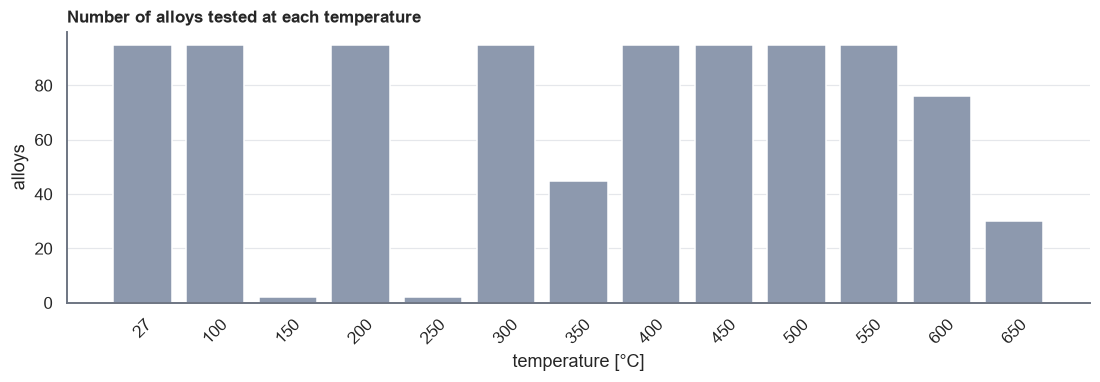

In [6]:
per_alloy = steel.groupby("alloy_id")
comp_unique = per_alloy[COMPOSITION].nunique().max(axis=1)
structure = {
    "tests": len(steel),
    "alloys": steel["alloy_id"].nunique(),
    "tests per alloy (min / median / max)": f"{per_alloy.size().min()} / {per_alloy.size().median():.0f} / {per_alloy.size().max()}",
    "alloys with inconsistent composition": int((comp_unique > 1).sum()),
    "distinct test temperatures": steel["temperature_C"].nunique(),
    "temperature range [°C]": f"{steel['temperature_C'].min():.0f} – {steel['temperature_C'].max():.0f}",
    "missing values": int(steel.isna().sum().sum()),
    "duplicate rows": int(steel.duplicated().sum()),
}
display(pd.Series(structure, name="value").to_frame())

alloy_comp = per_alloy[COMPOSITION].first()
element_profile = pd.DataFrame({
    "alloys with zero": (alloy_comp == 0).mean(),
    "min": alloy_comp.min(), "median": alloy_comp.median(), "max": alloy_comp.max(),
    "CV": alloy_comp.std() / alloy_comp.mean().replace(0, np.nan),
})
display(element_profile.style.format(precision=3).format("{:.0%}", subset=["alloys with zero"])
        .background_gradient(subset=["alloys with zero"], cmap="Greys"))

ELEMENTS = [c for c in COMPOSITION if element_profile.loc[c, "alloys with zero"] < 0.5 and alloy_comp[c].nunique() > 1]
EXCLUDED = [c for c in COMPOSITION if c not in ELEMENTS]
print(f"Composition variables retained: {ELEMENTS}")
print(f"Excluded (constant or zero for ≥50 % of alloys): {EXCLUDED or 'none'}")

fig, ax = plt.subplots(figsize=(12, 3.2))
grid = pd.crosstab(steel["alloy_id"], steel["temperature_C"]).gt(0).sum()
ax.bar(grid.index.astype(str), grid.values, color=SLATE)
ax.set(title="Number of alloys tested at each temperature", xlabel="temperature [°C]", ylabel="alloys")
ax.tick_params(axis="x", rotation=45)
keep(fig, "3_1_temperature_grid")
plt.show()

### 3.2 Physical constraints
Checks that must hold for any valid tensile test:
- the proof stress cannot exceed the tensile strength;
- elongation and reduction in area must lie between 0 and 100 %;
- all stresses must be positive.

In [7]:
violations = pd.DataFrame({
    "Rp0.2 > Rm": steel["proof_stress_MPa"] > steel["tensile_strength_MPa"],
    "A outside (0, 100]": ~steel["elongation_pct"].between(0, 100, inclusive="right"),
    "Z outside (0, 100]": ~steel["reduction_area_pct"].between(0, 100, inclusive="right"),
    "non-positive stress": (steel[["proof_stress_MPa", "tensile_strength_MPa"]] <= 0).any(axis=1),
})
display(violations.sum().rename("violations").to_frame().T)
if violations.any(axis=1).any():
    display(steel[violations.any(axis=1)])
steel["yield_ratio"] = steel["proof_stress_MPa"] / steel["tensile_strength_MPa"]

,Rp0.2 > Rm,"A outside (0, 100]","Z outside (0, 100]",non-positive stress
violations,1,0,0,0


,alloy_id,C,Si,Mn,P,S,Ni,Cr,Mo,Cu,V,Al,N,Ceq,Nb_Ta,temperature_C,proof_stress_MPa,tensile_strength_MPa,elongation_pct,reduction_area_pct
680,VbN,0.15,0.52,0.78,0.01,0.009,0.12,1.17,0.98,0.08,0.23,0.003,0.0106,0.0,0.0,550,408,162,18,80


### 3.3 Statistical outlier detection
The original analysis corrected a single suspicious value (alloy CbC) by inspecting it manually. Here the same idea is applied to every alloy and every property systematically:

1. For each alloy and property, a quadratic trend in temperature is fitted.
2. Residuals are standardised with a robust scale, the median absolute deviation (MAD) pooled over all alloys.
3. A point is flagged if $|z| >$ `outlier_z`.

A flagged value is removed **only from the model of the property concerned**. The other properties from the same test are kept.

**38 tests with at least one flagged property** (|z| > 4.0)

,alloy_id,temperature_C,proof_stress_MPa,tensile_strength_MPa,elongation_pct,reduction_area_pct,z_proof_stress_MPa,z_tensile_strength_MPa,z_elongation_pct,z_reduction_area_pct
29,MBD,650,143,221,60,91,-1.54,-1.17,4.08,-0.43
87,MBL,550,251,395,27,82,1.33,1.02,-4.47,0.54
88,MBL,600,220,317,33,84,1.16,-0.03,-5.78,-0.27
89,MBL,650,137,213,78,90,-1.90,-1.80,8.20,-0.02
203,LAB,300,185,574,29,35,-2.38,1.12,2.11,-6.41
221,LAD,300,178,524,28,36,-1.96,1.20,1.65,-6.10
230,LAE,300,218,530,27,37,-1.87,1.33,1.25,-5.61
239,LAF,300,203,487,28,42,-0.79,0.58,1.08,-6.04
248,LAG,300,278,557,24,28,-0.59,1.33,1.26,-6.52
264,LAJ,100,408,512,20,64,4.42,0.38,-1.52,1.17


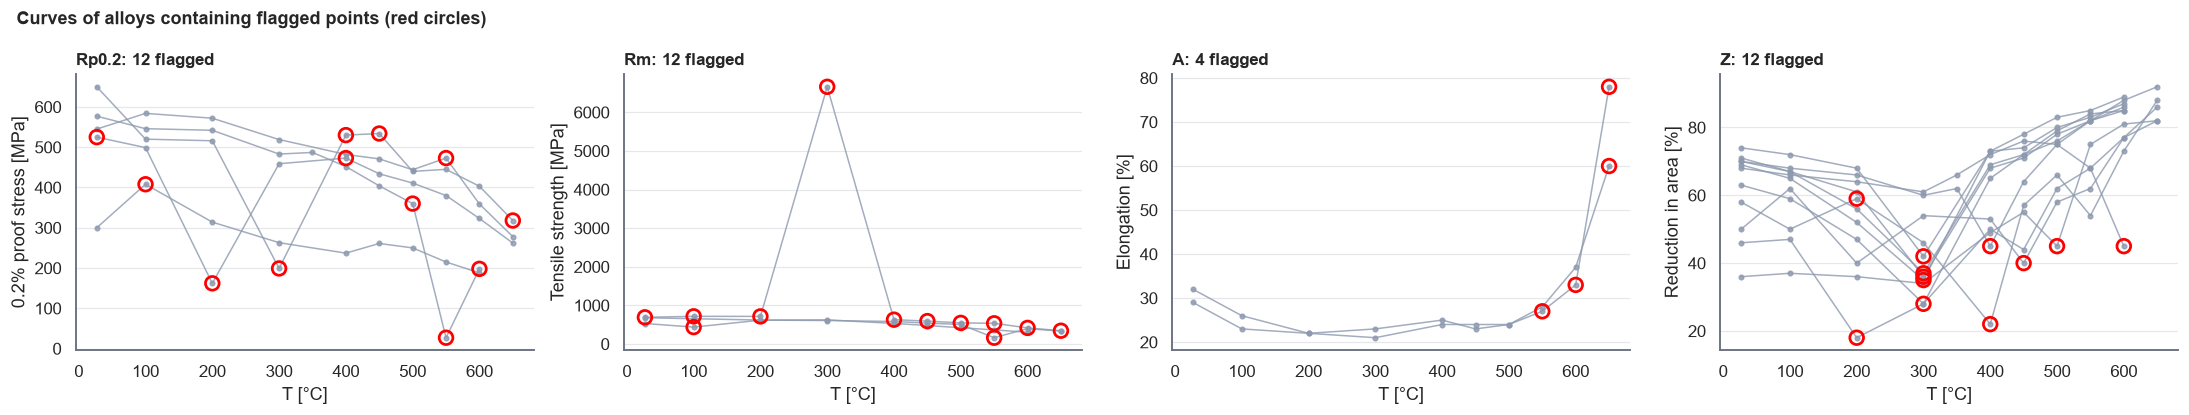

,proof_stress_MPa,tensile_strength_MPa,elongation_pct,reduction_area_pct
usable observations,902,903,910,902


In [8]:
def trend_residuals(frame, prop):
    res = pd.Series(np.nan, index=frame.index)
    for _, g in frame.groupby("alloy_id"):
        g = g.dropna(subset=[prop])
        if len(g) >= 5:
            t = g["temperature_C"].to_numpy() / 100
            coef = np.polyfit(t, g[prop].to_numpy(), 2)
            res.loc[g.index] = g[prop].to_numpy() - np.polyval(coef, t)
    return res


flags = {}
for prop in PROPS:
    r = trend_residuals(steel, prop)
    scale = stats.median_abs_deviation(r.dropna(), scale="normal")
    steel[f"z_{prop}"] = r / scale
    flags[prop] = steel[f"z_{prop}"].abs() > CFG["outlier_z"]

flag_table = steel.loc[pd.DataFrame(flags).any(axis=1), ["alloy_id", "temperature_C"] + PROPS + [f"z_{p}" for p in PROPS]]
say(f"**{len(flag_table)} tests with at least one flagged property** (|z| > {CFG['outlier_z']})")
display(flag_table.style.format(precision=2).background_gradient(subset=[f"z_{p}" for p in PROPS], cmap="RdBu_r", vmin=-8, vmax=8))

fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
for ax, prop in zip(axes, PROPS):
    for alloy in steel.loc[flags[prop], "alloy_id"].unique():
        g = steel[steel["alloy_id"] == alloy].sort_values("temperature_C")
        ax.plot(g["temperature_C"], g[prop], "-o", ms=3, lw=1, color=SLATE, alpha=0.8)
    f = steel[flags[prop]]
    ax.scatter(f["temperature_C"], f[prop], s=80, facecolor="none", edgecolor="red", lw=1.8, zorder=5)
    ax.set(title=f"{PROP_SHORT[prop]}: {int(flags[prop].sum())} flagged", xlabel="T [°C]", ylabel=PROP_LABELS[prop])
fig.suptitle("Curves of alloys containing flagged points (red circles)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
keep(fig, "3_3_outliers")
plt.show()

clean = steel.copy()
for prop in PROPS:
    clean.loc[flags[prop] | violations.any(axis=1), prop] = np.nan
display(clean[PROPS].notna().sum().rename("usable observations").to_frame().T)

## 4 · Exploratory Metallurgy

### 4.1 Temperature response
Each alloy's curve is drawn as a thin line, with the across-alloy median and interquartile band on top. The panels show how strength softens with temperature, and whether ductility responds consistently across alloys or depends on the individual alloy.

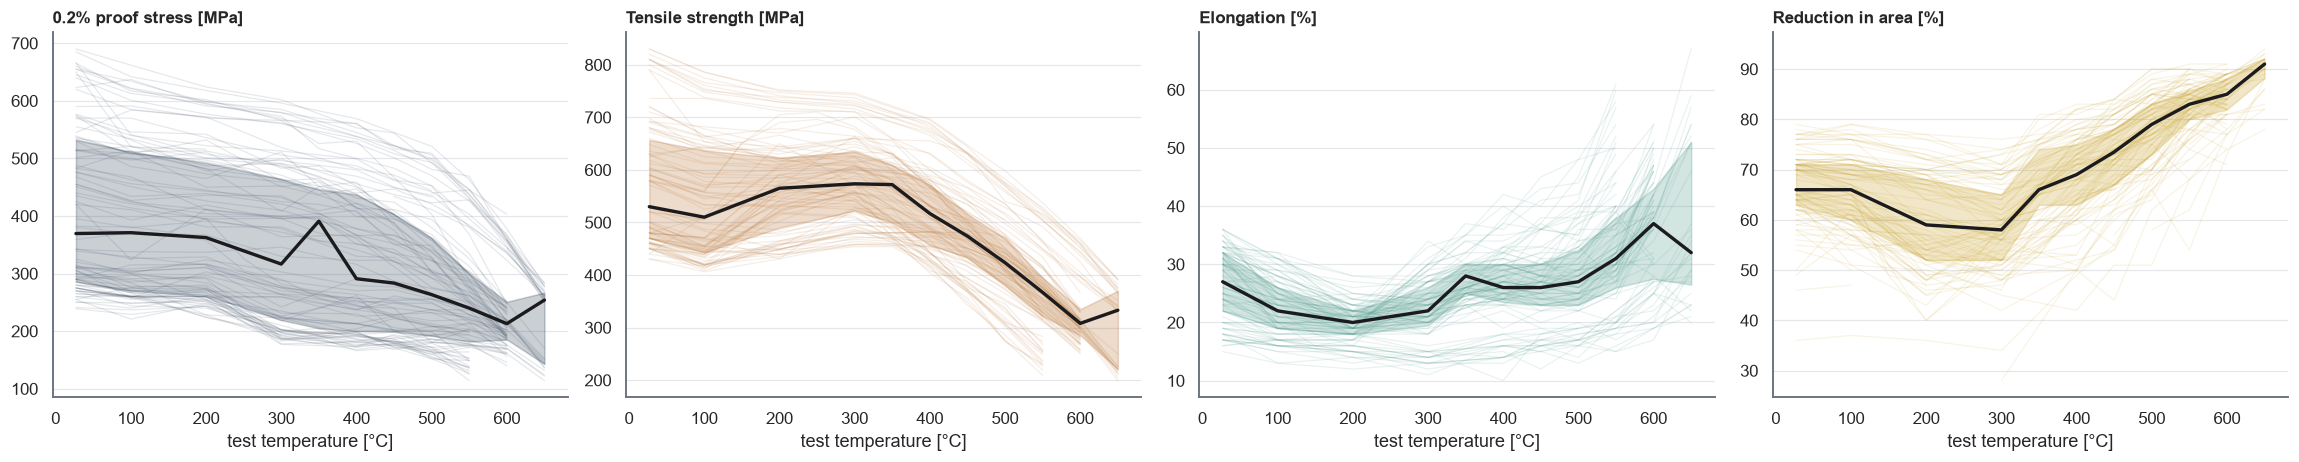

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.3))
for ax, prop in zip(axes, PROPS):
    for _, g in clean.groupby("alloy_id"):
        g = g.sort_values("temperature_C")
        ax.plot(g["temperature_C"], g[prop], color=PROP_COLORS[prop], alpha=0.12, lw=0.8)
    q = clean.groupby("temperature_C")[prop].quantile([0.25, 0.5, 0.75]).unstack()
    q = q[clean.groupby("temperature_C")[prop].count() >= 5]
    ax.fill_between(q.index, q[0.25], q[0.75], color=PROP_COLORS[prop], alpha=0.25)
    ax.plot(q.index, q[0.5], color=GRAPHITE, lw=2.2)
    ax.set(title=PROP_LABELS[prop], xlabel="test temperature [°C]")
fig.tight_layout()
keep(fig, "4_1_temperature_response")
plt.show()

### 4.2 How consistently properties respond to temperature
For each alloy, the Spearman correlation between temperature and each property is computed. The distributions across the 95 alloys summarise all the per-alloy correlation heatmaps from the original analysis in one view. A narrow distribution means every alloy responds in the same direction. A wide one means the temperature dependence varies from alloy to alloy.

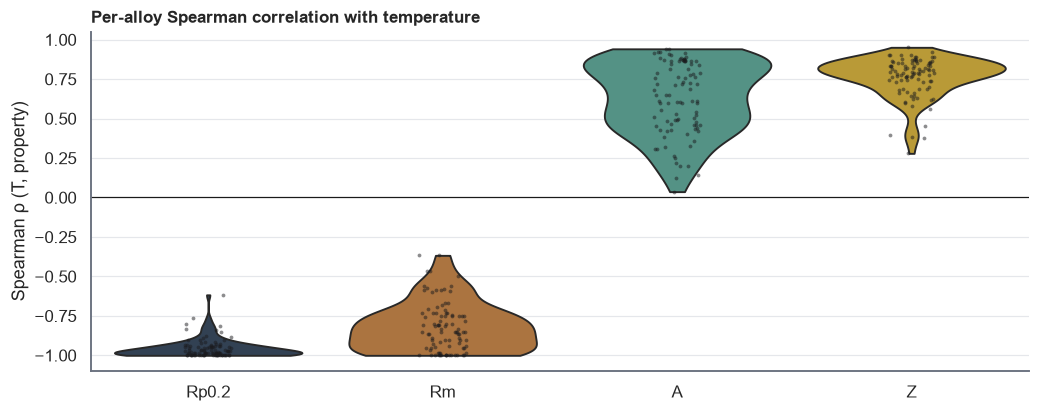

,mean,25%,50%,75%,share negative
Rp0.2,-0.96,-1.00,-0.98,-0.94,1.00
Rm,-0.82,-0.95,-0.85,-0.73,0.99
A,0.63,0.46,0.65,0.86,0.00
Z,0.77,0.73,0.79,0.85,0.00


In [10]:
rho = clean.groupby("alloy_id").apply(
    lambda g: pd.Series({p: stats.spearmanr(g["temperature_C"], g[p], nan_policy="omit").statistic for p in PROPS}))
fig, ax = plt.subplots(figsize=(11, 4))
long = rho.melt(var_name="property", value_name="rho").dropna()
long["property"] = long["property"].map(PROP_SHORT)
sns.violinplot(data=long, x="property", y="rho", hue="property", inner=None, cut=0, ax=ax, legend=False,
               palette={PROP_SHORT[p]: PROP_COLORS[p] for p in PROPS}, saturation=0.8)
sns.stripplot(data=long, x="property", y="rho", color=GRAPHITE, size=2.5, alpha=0.5, ax=ax)
ax.axhline(0, c="k", lw=0.8)
ax.set(title="Per-alloy Spearman correlation with temperature", xlabel="", ylabel="Spearman ρ (T, property)")
keep(fig, "4_2_per_alloy_rho")
plt.show()
display(rho.describe().T[["mean", "25%", "50%", "75%"]].assign(**{"share negative": (rho < 0).mean()})
        .rename(index=PROP_SHORT).style.format(precision=2))

### 4.3 Strength–ductility relationships
The pairwise relations between the four properties, with points coloured by temperature, together with the distribution of the yield ratio $R_{p0.2}/R_m$. A strong negative link between strength and ductility means that a model predicting all four properties must reproduce this trade-off.

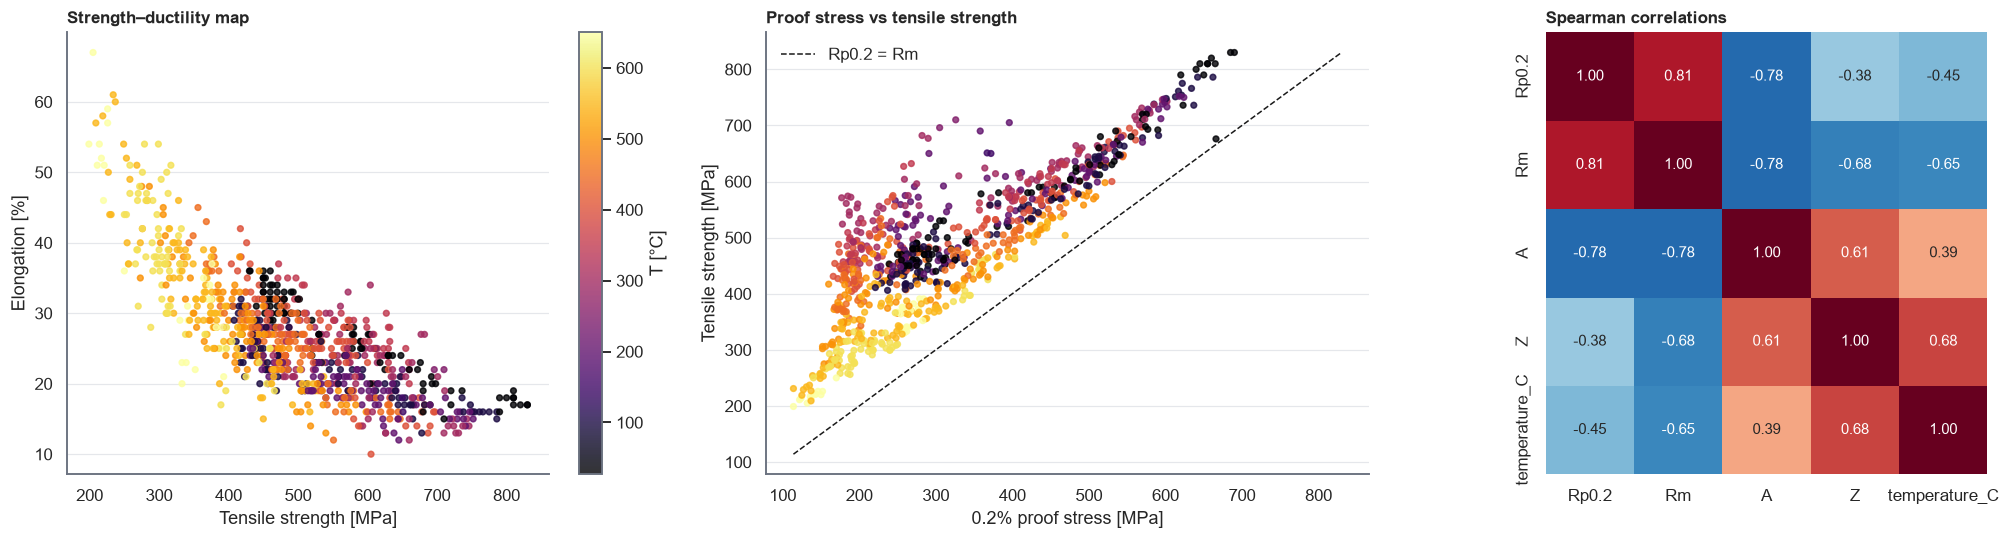

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sc = axes[0].scatter(clean["tensile_strength_MPa"], clean["elongation_pct"], c=clean["temperature_C"], cmap="inferno",
                     s=14, alpha=0.8)
axes[0].set(xlabel=PROP_LABELS["tensile_strength_MPa"], ylabel=PROP_LABELS["elongation_pct"], title="Strength–ductility map")
fig.colorbar(sc, ax=axes[0], label="T [°C]")
axes[1].scatter(clean["proof_stress_MPa"], clean["tensile_strength_MPa"], c=clean["temperature_C"], cmap="inferno", s=14, alpha=0.8)
lim = [clean[["proof_stress_MPa", "tensile_strength_MPa"]].min().min(), clean[["proof_stress_MPa", "tensile_strength_MPa"]].max().max()]
axes[1].plot(lim, lim, "k--", lw=1, label="Rp0.2 = Rm")
axes[1].set(xlabel=PROP_LABELS["proof_stress_MPa"], ylabel=PROP_LABELS["tensile_strength_MPa"], title="Proof stress vs tensile strength")
axes[1].legend()
sns.heatmap(clean[PROPS + ["temperature_C"]].corr(method="spearman").rename(index=PROP_SHORT, columns=PROP_SHORT),
            annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[2], cbar=False, square=True)
axes[2].set_title("Spearman correlations")
fig.tight_layout()
keep(fig, "4_3_strength_ductility")
plt.show()

### 4.4 Composition space
Composition is analysed **at the alloy level**, one row per steel, so that alloys tested at more temperatures do not carry more weight. A principal component analysis of the standardised compositions shows how the 95 grades are spread through composition space and whether there are distinct steel families. Points are coloured by room-temperature tensile strength.

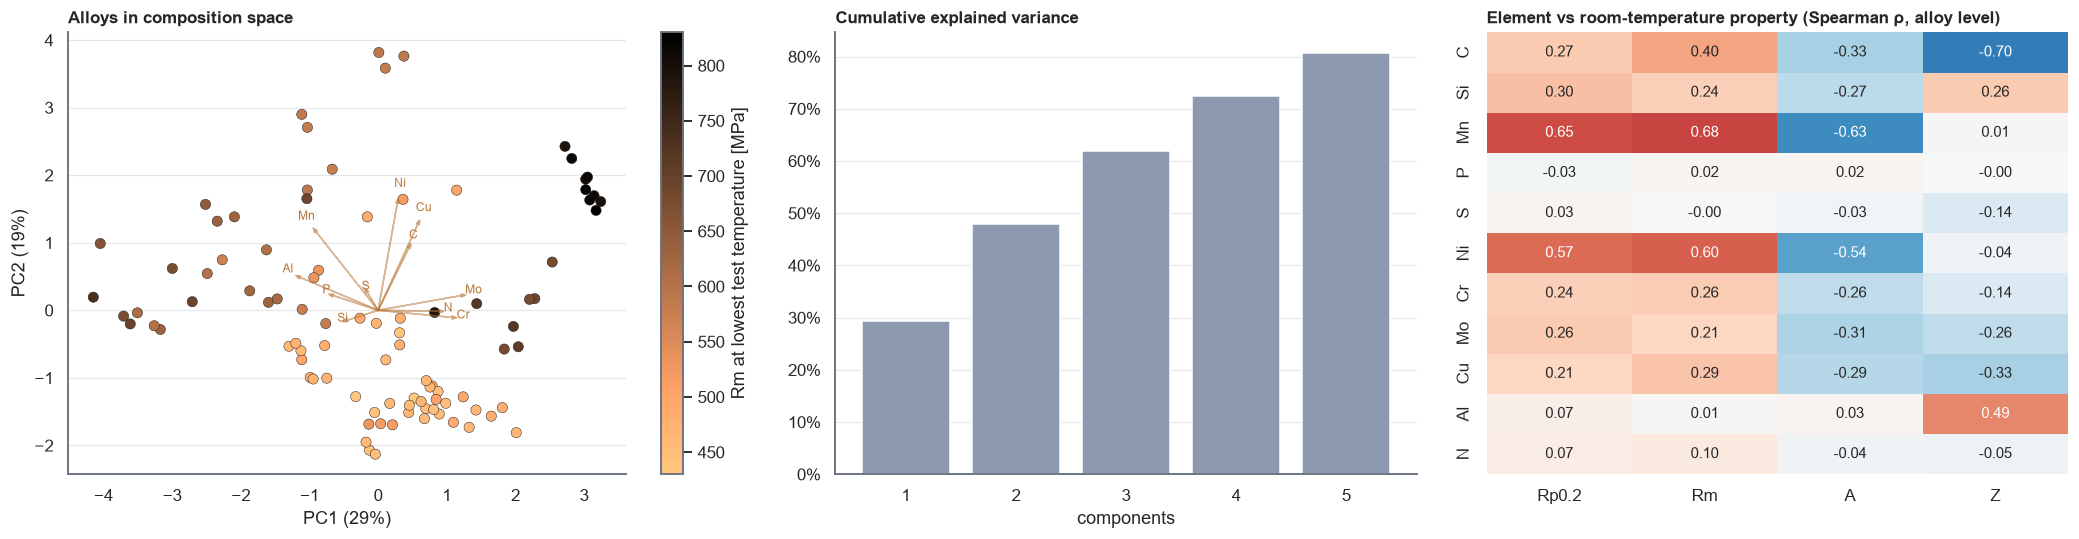

In [12]:
rt = clean[clean["temperature_C"] == clean["temperature_C"].min()].groupby("alloy_id")[PROPS].mean()
alloy_table = alloy_comp[ELEMENTS].join(rt)
Zc = StandardScaler().fit_transform(alloy_table[ELEMENTS])
pca = PCA(n_components=min(5, len(ELEMENTS)), random_state=SEED).fit(Zc)
scores = pca.transform(Zc)

fig, axes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
sc = axes[0].scatter(scores[:, 0], scores[:, 1], c=alloy_table["tensile_strength_MPa"], cmap="copper_r", s=45, edgecolor="k", lw=0.3)
fig.colorbar(sc, ax=axes[0], label="Rm at lowest test temperature [MPa]")
axes[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
            title="Alloys in composition space")
load = pd.DataFrame(pca.components_[:2].T, index=ELEMENTS, columns=["PC1", "PC2"])
for el, (a, b) in load.iterrows():
    axes[0].annotate(el, (a * 3, b * 3), color=COPPER, fontsize=8, ha="center")
    axes[0].arrow(0, 0, a * 2.6, b * 2.6, color=COPPER, alpha=0.5, head_width=0.05)
axes[1].bar(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), color=SLATE)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set(title="Cumulative explained variance", xlabel="components")

comp_effect = pd.DataFrame({p: {el: stats.spearmanr(alloy_table[el], alloy_table[p], nan_policy="omit").statistic for el in ELEMENTS}
                            for p in PROPS}).rename(columns=PROP_SHORT)
sns.heatmap(comp_effect, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[2], cbar=False)
axes[2].set_title("Element vs room-temperature property (Spearman ρ, alloy level)")
fig.tight_layout()
keep(fig, "4_4_composition_space")
plt.show()

## 5 · Feature Engineering

Two feature sets are compared throughout the study:

| Set | Content |
|---|---|
| **original** | C, Mn, Cr, Ni, Al, T, plus the interactions from the original analysis: $T^2$ and $T\times$element for each of the five elements |
| **full** | every retained composition variable, T, $T^2$, the IIW carbon equivalent, and temperature interactions with CE, C, Mn, Cr, Ni, Mo and Al |

The IIW carbon equivalent $CE = C + \frac{Mn}{6} + \frac{Cr+Mo+V}{5} + \frac{Ni+Cu}{15}$ summarises hardenability in a single index. Features are computed inside the model pipeline from the raw composition and temperature. This means every analysis that varies an input, such as permutation importance and the ICE profiles, keeps the derived features consistent with the input that was changed.

In [13]:
RAW_INPUTS = ELEMENTS + ["temperature_C"]
ORIGINAL_ELEMENTS = [e for e in ["C", "Mn", "Cr", "Ni", "Al"] if e in ELEMENTS]


def carbon_equivalent(df):
    g = lambda e: df[e] if e in df else 0.0
    return g("C") + g("Mn") / 6 + (g("Cr") + g("Mo") + g("V")) / 5 + (g("Ni") + g("Cu")) / 15


def engineer(df, feature_set="full"):
    t = df["temperature_C"] / 100.0
    out = {}
    if feature_set == "original":
        for e in ORIGINAL_ELEMENTS:
            out[e] = df[e]
        out["T"], out["T2"] = t, t ** 2
        for e in ORIGINAL_ELEMENTS:
            out[f"T_x_{e}"] = t * df[e]
    else:
        for e in ELEMENTS:
            out[e] = df[e]
        ce = carbon_equivalent(df)
        out["T"], out["T2"], out["CE"], out["T_x_CE"] = t, t ** 2, ce, t * ce
        for e in ["C", "Mn", "Cr", "Ni", "Mo", "Al"]:
            if e in ELEMENTS:
                out[f"T_x_{e}"] = t * df[e]
    return pd.DataFrame(out, index=df.index)


FEATURE_SETS = ["original", "full"]
for fs in FEATURE_SETS:
    print(f"{fs:<9} {engineer(clean.head(), fs).shape[1]:>2} features: {', '.join(engineer(clean.head(), fs).columns)}")

original  12 features: C, Mn, Cr, Ni, Al, T, T2, T_x_C, T_x_Mn, T_x_Cr, T_x_Ni, T_x_Al
full      21 features: C, Si, Mn, P, S, Ni, Cr, Mo, Cu, Al, N, T, T2, CE, T_x_CE, T_x_C, T_x_Mn, T_x_Cr, T_x_Ni, T_x_Mo, T_x_Al


## 6 · Validation Design

A test set of **unseen alloys** is held out, 20 % of the alloy codes, and is used only in §9. Cross-validation on the remaining alloys uses `GroupKFold` with the alloy as the group.

The effect of row-wise splitting, as used in the original analysis, is measured next. A default random forest is evaluated both ways, and the gap between the two scores shows how optimistic row-wise validation is for a model that is meant to be applied to new steels.

In [14]:
splitter = GroupShuffleSplit(n_splits=1, test_size=CFG["test_alloy_fraction"], random_state=SEED)
train_idx, test_idx = next(splitter.split(clean, groups=clean["alloy_id"]))
train, test = clean.iloc[train_idx].copy(), clean.iloc[test_idx].copy()
GCV = GroupKFold(n_splits=CFG["cv_folds"])
RCV = KFold(n_splits=CFG["cv_folds"], shuffle=True, random_state=SEED)
assert not set(train["alloy_id"]) & set(test["alloy_id"])

display(pd.DataFrame({"alloys": [train["alloy_id"].nunique(), test["alloy_id"].nunique()],
                      "tests": [len(train), len(test)]}, index=["train", "test"]))


def target_data(frame, prop):
    d = frame.dropna(subset=[prop])
    return d[RAW_INPUTS], d[prop], d["alloy_id"]


def probe_pipeline(fs="full"):
    return Pipeline([("features", FunctionTransformer(engineer, kw_args={"feature_set": fs})),
                     ("model", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))])


leak = []
for prop in PROPS:
    X, y, g = target_data(train, prop)
    row = cross_validate(probe_pipeline(), X, y, cv=RCV, scoring=("r2", "neg_root_mean_squared_error"))
    grp = cross_validate(probe_pipeline(), X, y, cv=GCV, groups=g, scoring=("r2", "neg_root_mean_squared_error"))
    leak.append({"property": PROP_SHORT[prop], "R² row-wise": row["test_r2"].mean(), "R² alloy-grouped": grp["test_r2"].mean(),
                 "RMSE row-wise": -row["test_neg_root_mean_squared_error"].mean(),
                 "RMSE alloy-grouped": -grp["test_neg_root_mean_squared_error"].mean()})
leak = pd.DataFrame(leak).set_index("property")
leak["optimism (ΔR²)"] = leak["R² row-wise"] - leak["R² alloy-grouped"]
display(leak.style.format(precision=3).background_gradient(subset=["optimism (ΔR²)"], cmap="Reds"))

,alloys,tests
train,76,735
test,19,180


,R² row-wise,R² alloy-grouped,RMSE row-wise,RMSE alloy-grouped,optimism (ΔR²)
property,,,,,
Rp0.2,0.971,0.878,21.997,43.731,0.093
Rm,0.958,0.928,25.410,32.324,0.029
A,0.860,0.855,3.195,3.219,0.006
Z,0.877,0.793,4.137,5.403,0.085


## 7 · Model Benchmark

### 7.1 Model library
Thirteen regressors from six families:

| Family | Models |
|---|---|
| Linear | Ridge, Ridge with degree-2 polynomial features, Lasso, Elastic Net |
| Bagged trees | Random Forest, Extra Trees |
| Boosted trees | XGBoost, LightGBM, CatBoost |
| Kernel | Gaussian Process (ARD RBF + white noise), Support Vector Regression (RBF) |
| Instance-based | k-Nearest Neighbours |
| Neural | Multilayer Perceptron |

All inputs are standardised. SVR and the MLP also standardise the target through `TransformedTargetRegressor`. The Gaussian process fits its own kernel hyperparameters by maximising the marginal likelihood, so it is not included in the randomised search.

In [15]:
MODELS = {"RIDGE": "Ridge", "RIDGE_POLY": "Ridge (poly-2)", "LASSO": "Lasso", "ENET": "Elastic Net",
          "RF": "Random Forest", "ET": "Extra Trees", "XGB": "XGBoost", "LGBM": "LightGBM", "CAT": "CatBoost",
          "GP": "Gaussian Process", "SVR": "SVR", "KNN": "k-NN", "MLP": "MLP"}
FAMILY = {"RIDGE": "linear", "RIDGE_POLY": "linear", "LASSO": "linear", "ENET": "linear", "RF": "bagged trees",
          "ET": "bagged trees", "XGB": "boosted trees", "LGBM": "boosted trees", "CAT": "boosted trees",
          "GP": "kernel", "SVR": "kernel", "KNN": "instance", "MLP": "neural"}
FAMILY_COLORS = {"linear": SLATE, "bagged trees": "#4C9A8A", "boosted trees": COPPER, "kernel": STEEL,
                 "instance": "#C9A227", "neural": "#7B2D26"}
TARGET_SCALED = {"SVR", "MLP"}


def base_estimator(key, n_features):
    if key in ("RIDGE", "RIDGE_POLY"):
        return Ridge(alpha=1.0)
    if key == "LASSO":
        return Lasso(alpha=0.1, max_iter=50000)
    if key == "ENET":
        return ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=50000)
    if key == "RF":
        return RandomForestRegressor(n_estimators=400, n_jobs=1, random_state=SEED)
    if key == "ET":
        return ExtraTreesRegressor(n_estimators=400, n_jobs=1, random_state=SEED)
    if key == "XGB":
        return XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.9, colsample_bytree=0.8,
                            tree_method="hist", n_jobs=1, random_state=SEED)
    if key == "LGBM":
        return LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=15, min_child_samples=5,
                             n_jobs=1, random_state=SEED, verbose=-1)
    if key == "CAT":
        return CatBoostRegressor(iterations=800, learning_rate=0.05, depth=5, random_seed=SEED, verbose=0,
                                 thread_count=1, allow_writing_files=False)
    if key == "GP":
        kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBF(np.ones(n_features), (1e-2, 1e3)) + WhiteKernel(0.1, (1e-6, 1.0))
        return GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=0, random_state=SEED)
    if key == "SVR":
        return SVR(C=10.0, epsilon=0.05, gamma="scale")
    if key == "KNN":
        return KNeighborsRegressor(n_neighbors=5, weights="distance")
    if key == "MLP":
        return MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=3000, early_stopping=True,
                            n_iter_no_change=30, random_state=SEED)
    raise KeyError(key)


def build(key, feature_set="full"):
    n_features = engineer(clean.head(), feature_set).shape[1]
    est = base_estimator(key, n_features)
    if key in TARGET_SCALED:
        est = TransformedTargetRegressor(regressor=est, transformer=StandardScaler())
    steps = [("features", FunctionTransformer(engineer, kw_args={"feature_set": feature_set})), ("scale", StandardScaler())]
    if key == "RIDGE_POLY":
        steps += [("poly", PolynomialFeatures(2, include_bias=False)), ("scale2", StandardScaler())]
    return Pipeline(steps + [("model", est)])


def param_prefix(key):
    return "model__regressor__" if key in TARGET_SCALED else "model__"

### 7.2 Screening: every model × property × feature set
Default configurations are scored with 5-fold alloy-grouped cross-validation. R² is shown as a heatmap for each feature set. The chart underneath shows, for each model and property, how much the full chemistry improves on the original six features.

Rp0.2  screened (218 s)


Rm     screened (349 s)


A      screened (495 s)


Z      screened (620 s)


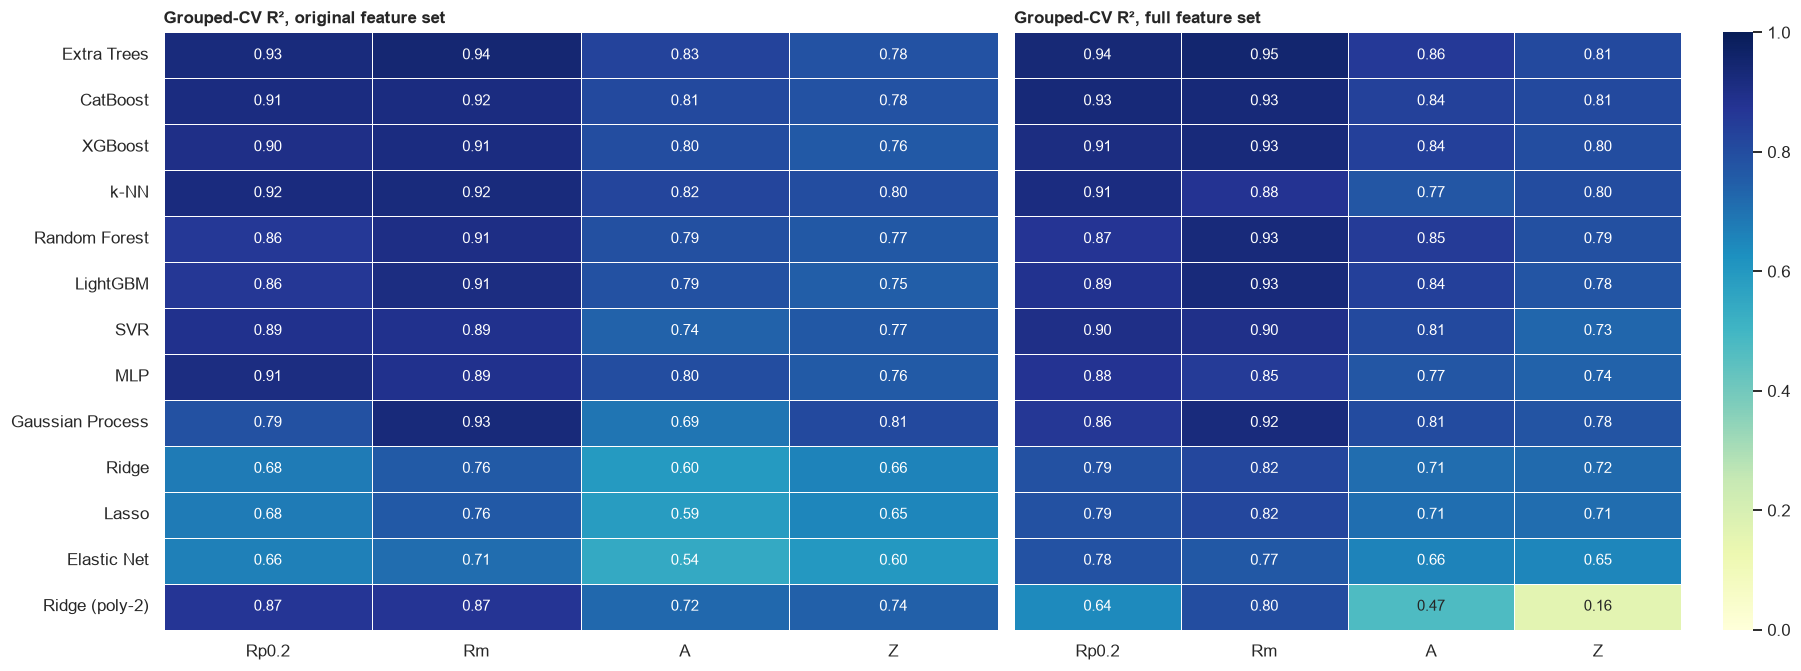

In [16]:
SCORING = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}
screen_rows = []
t_start = time.time()
for prop in PROPS:
    X, y, g = target_data(train, prop)
    for fs in FEATURE_SETS:
        for key in MODELS:
            res = cross_validate(build(key, fs), X, y, cv=GCV, groups=g, scoring=SCORING, n_jobs=-1)
            screen_rows.append({"property": prop, "feature_set": fs, "model": key,
                                "R2": res["test_r2"].mean(), "R2_sd": res["test_r2"].std(),
                                "RMSE": -res["test_rmse"].mean(), "MAE": -res["test_mae"].mean(),
                                "fold_rmse": -res["test_rmse"]})
    print(f"{PROP_SHORT[prop]:<6} screened ({time.time() - t_start:.0f} s)")
screen = pd.DataFrame(screen_rows)
keep_table(screen.drop(columns="fold_rmse"), "7_2_screening")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2), sharey=True)
for ax, fs in zip(axes, FEATURE_SETS):
    piv = screen[screen["feature_set"] == fs].pivot(index="model", columns="property", values="R2")
    piv = piv.loc[screen.groupby("model")["R2"].mean().sort_values(ascending=False).index, PROPS]
    sns.heatmap(piv.rename(index=MODELS, columns=PROP_SHORT), annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1,
                ax=ax, cbar=fs == "full", linewidths=0.6)
    ax.set(title=f"Grouped-CV R², {fs} feature set", xlabel="", ylabel="")
fig.tight_layout()
keep(fig, "7_2_screening_heatmap")
plt.show()

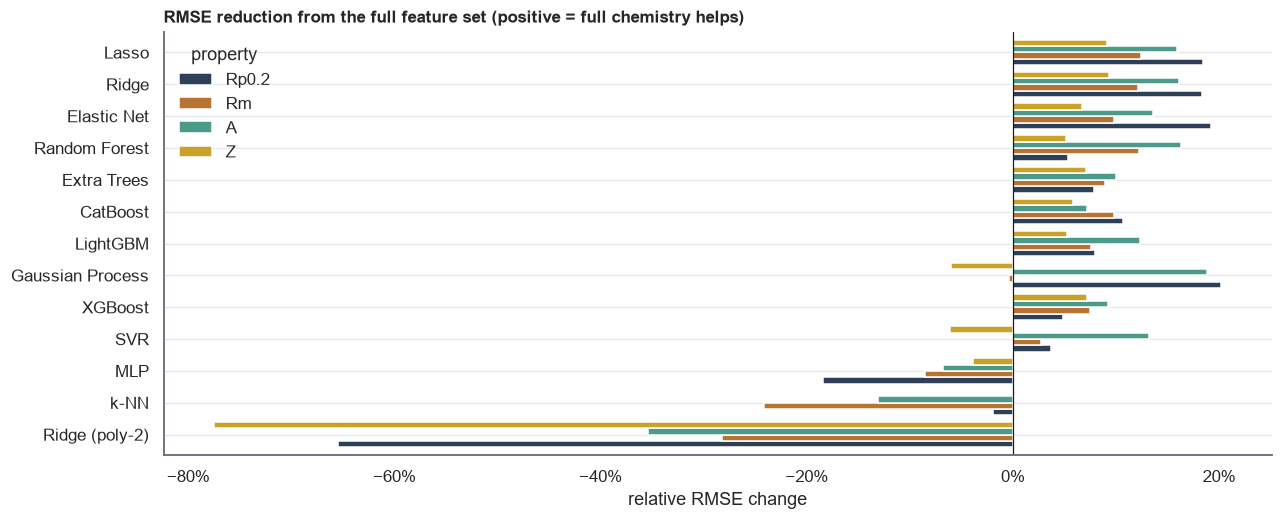

property,A,Rp0.2,Z,Rm
feature set used for tuning,full,full,full,full


In [17]:
def corrected_ttest(a, b, k=CFG["cv_folds"]):
    d = np.asarray(a) - np.asarray(b)
    se = np.sqrt((1 / len(d) + 1 / (k - 1)) * d.var(ddof=1))
    return (d.mean(), 2 * stats.t.sf(abs(d.mean() / se), len(d) - 1)) if se > 0 else (d.mean(), np.nan)


gain_rows = []
for (prop, key), g in screen.groupby(["property", "model"]):
    o, f = g.set_index("feature_set").loc["original"], g.set_index("feature_set").loc["full"]
    d, p = corrected_ttest(o["fold_rmse"], f["fold_rmse"])
    gain_rows.append({"property": PROP_SHORT[prop], "model": MODELS[key], "RMSE reduction": d,
                      "relative": d / o["RMSE"], "p": p})
gain = pd.DataFrame(gain_rows)
fig, ax = plt.subplots(figsize=(13, 5))
piv = gain.pivot(index="model", columns="property", values="relative")[[PROP_SHORT[p] for p in PROPS]]
piv = piv.loc[piv.mean(axis=1).sort_values().index]
piv.plot(kind="barh", ax=ax, color=[PROP_COLORS[p] for p in PROPS], width=0.8)
ax.axvline(0, c="k", lw=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(title="RMSE reduction from the full feature set (positive = full chemistry helps)", xlabel="relative RMSE change", ylabel="")
ax.grid(axis="x")
keep(fig, "7_2_feature_set_gain")
plt.show()

best_fs = (screen.groupby(["property", "feature_set"])["RMSE"].min().unstack().idxmin(axis=1))
display(best_fs.rename(index=PROP_SHORT).rename("feature set used for tuning").to_frame().T)
FEATURE_CHOICE = best_fs.to_dict()

## 8 · Hyperparameter Optimisation
Each of the 13 models is tuned separately for each property on that property's selected feature set. The search is a randomised search that minimises grouped-CV RMSE. Search spaces use log-uniform distributions for regularisation strengths and learning rates. The **champion** for each property is the model with the lowest tuned grouped-CV RMSE.

In [18]:
SPACES = {
    "RIDGE": {"alpha": loguniform(1e-3, 1e3)},
    "RIDGE_POLY": {"alpha": loguniform(1e-2, 1e4)},
    "LASSO": {"alpha": loguniform(1e-3, 10)},
    "ENET": {"alpha": loguniform(1e-3, 10), "l1_ratio": uniform(0.05, 0.9)},
    "RF": {"n_estimators": randint(200, 700), "max_depth": [None, 6, 10, 16], "min_samples_leaf": randint(1, 8),
           "max_features": ["sqrt", 0.5, 1.0]},
    "ET": {"n_estimators": randint(200, 700), "max_depth": [None, 6, 10, 16], "min_samples_leaf": randint(1, 8),
           "max_features": ["sqrt", 0.5, 1.0]},
    "XGB": {"n_estimators": randint(200, 1000), "learning_rate": loguniform(0.01, 0.3), "max_depth": randint(2, 8),
            "min_child_weight": loguniform(0.5, 10), "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
            "reg_lambda": loguniform(1e-2, 10)},
    "LGBM": {"n_estimators": randint(200, 1000), "learning_rate": loguniform(0.01, 0.3), "num_leaves": randint(4, 48),
             "min_child_samples": randint(3, 30), "subsample": uniform(0.6, 0.4), "subsample_freq": [1],
             "colsample_bytree": uniform(0.5, 0.5), "reg_lambda": loguniform(1e-3, 10)},
    "CAT": {"iterations": randint(300, 1200), "learning_rate": loguniform(0.02, 0.2), "depth": randint(3, 8),
            "l2_leaf_reg": loguniform(1, 10)},
    "GP": {},
    "SVR": {"C": loguniform(0.1, 1000), "epsilon": loguniform(1e-3, 0.5), "gamma": loguniform(1e-3, 1)},
    "KNN": {"n_neighbors": randint(2, 30), "weights": ["uniform", "distance"], "p": [1, 2]},
    "MLP": {"hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64), (128, 64, 32)], "alpha": loguniform(1e-5, 1),
            "learning_rate_init": loguniform(1e-4, 1e-2)},
}

tuned, tune_rows = {}, []
for prop in PROPS:
    X, y, g = target_data(train, prop)
    fs = FEATURE_CHOICE[prop]
    for key in MODELS:
        t0 = time.time()
        pipe = build(key, fs)
        space = {param_prefix(key) + k: v for k, v in SPACES[key].items()}
        if space and CFG["search_iter"][key] > 0:
            search = RandomizedSearchCV(pipe, space, n_iter=CFG["search_iter"][key], cv=GCV,
                                        scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=SEED, refit=True)
            search.fit(X, y, groups=g)
            model, cv_rmse = search.best_estimator_, -search.best_score_
            cv_sd = search.cv_results_["std_test_score"][search.best_index_]
            params = {k.split("__")[-1]: v for k, v in search.best_params_.items()}
        else:
            res = cross_validate(pipe, X, y, cv=GCV, groups=g, scoring="neg_root_mean_squared_error", n_jobs=-1)
            model, cv_rmse, cv_sd, params = pipe.fit(X, y), -res["test_score"].mean(), res["test_score"].std(), {}
        tuned[(prop, key)] = model
        default_rmse = screen.query("property == @prop and feature_set == @fs and model == @key")["RMSE"].iloc[0]
        tune_rows.append({"property": prop, "model": key, "default RMSE": default_rmse, "tuned RMSE": cv_rmse,
                          "tuned RMSE sd": cv_sd, "seconds": time.time() - t0,
                          "parameters": ", ".join(f"{k}={round(v, 4) if isinstance(v, float) else v}" for k, v in params.items())})
    print(f"{PROP_SHORT[prop]:<6} tuned")

tuning = pd.DataFrame(tune_rows)
tuning["improvement"] = 1 - tuning["tuned RMSE"] / tuning["default RMSE"]
CHAMPIONS = tuning.loc[tuning.groupby("property")["tuned RMSE"].idxmin()].set_index("property")["model"].to_dict()
keep_table(tuning, "8_tuning")
display(pd.Series({PROP_SHORT[p]: MODELS[k] for p, k in CHAMPIONS.items()}, name="champion").to_frame().T)

Rp0.2  tuned


Rm     tuned


A      tuned


Z      tuned


,A,Rp0.2,Z,Rm
champion,LightGBM,CatBoost,Extra Trees,XGBoost


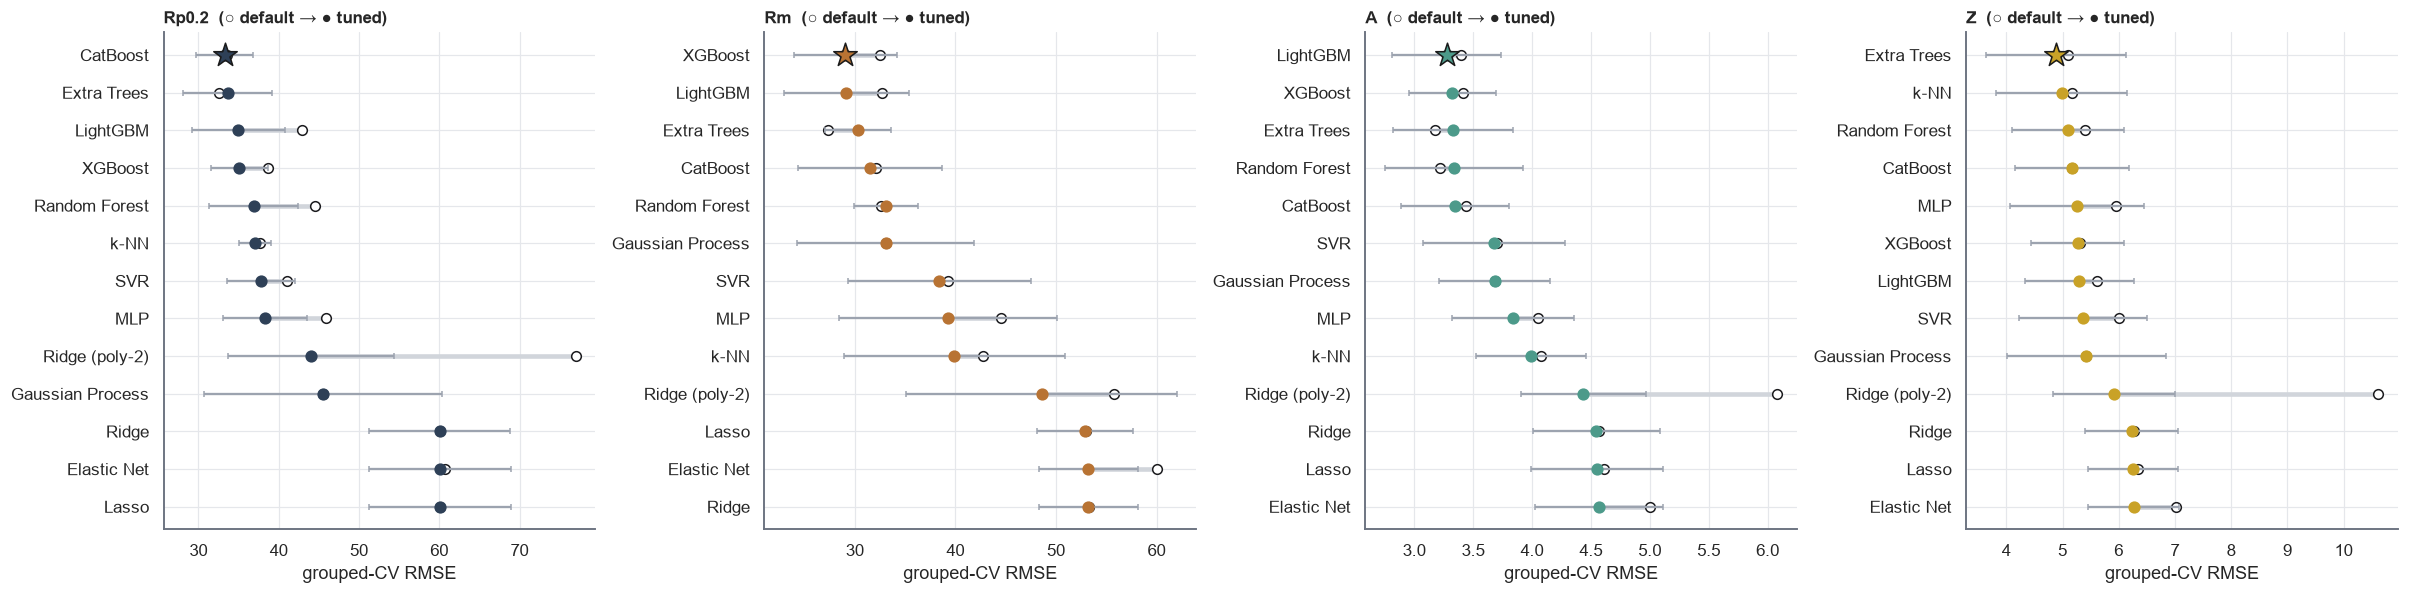

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5), sharey=False)
for ax, prop in zip(axes, PROPS):
    t = tuning[tuning["property"] == prop].sort_values("tuned RMSE", ascending=False)
    y = np.arange(len(t))
    ax.hlines(y, t["tuned RMSE"], t["default RMSE"], color="#D1D5DB", lw=3)
    ax.scatter(t["default RMSE"], y, facecolor="white", edgecolor=GRAPHITE, s=40, zorder=3)
    ax.errorbar(t["tuned RMSE"], y, xerr=t["tuned RMSE sd"], fmt="o", ms=7, ecolor="#9CA3AF", capsize=2, zorder=4,
                color=PROP_COLORS[prop])
    ax.scatter(t["tuned RMSE"].iloc[-1], y[-1], marker="*", s=260, color=PROP_COLORS[prop], edgecolor="k", zorder=5)
    ax.set_yticks(y, [MODELS[k] for k in t["model"]])
    ax.set(title=f"{PROP_SHORT[prop]}  (○ default → ● tuned)", xlabel="grouped-CV RMSE")
    ax.grid(axis="x")
fig.tight_layout()
keep(fig, "8_tuning_overview")
plt.show()

## 9 · Hold-out Evaluation on Unseen Alloys

### 9.1 Scores
Every tuned model is scored on the test alloys, none of which were seen during training. The 95 % confidence intervals for the champions come from a **cluster bootstrap** that resamples whole alloys, which respects the grouped structure of the data.

,champion,R²,R² 95% CI,RMSE,RMSE 95% CI,MAE,MAPE %
property,,,,,,,
Elongation [%],LightGBM,0.830,0.752 – 0.884,3.433,2.8 – 4.0,2.331,8.029
0.2% proof stress [MPa],CatBoost,0.943,0.900 – 0.973,31.366,22.3 – 40.1,23.240,8.331
Reduction in area [%],Extra Trees,0.871,0.785 – 0.927,4.103,3.2 – 5.0,3.046,4.743
Tensile strength [MPa],XGBoost,0.920,0.858 – 0.963,35.031,25.0 – 44.1,25.923,5.224


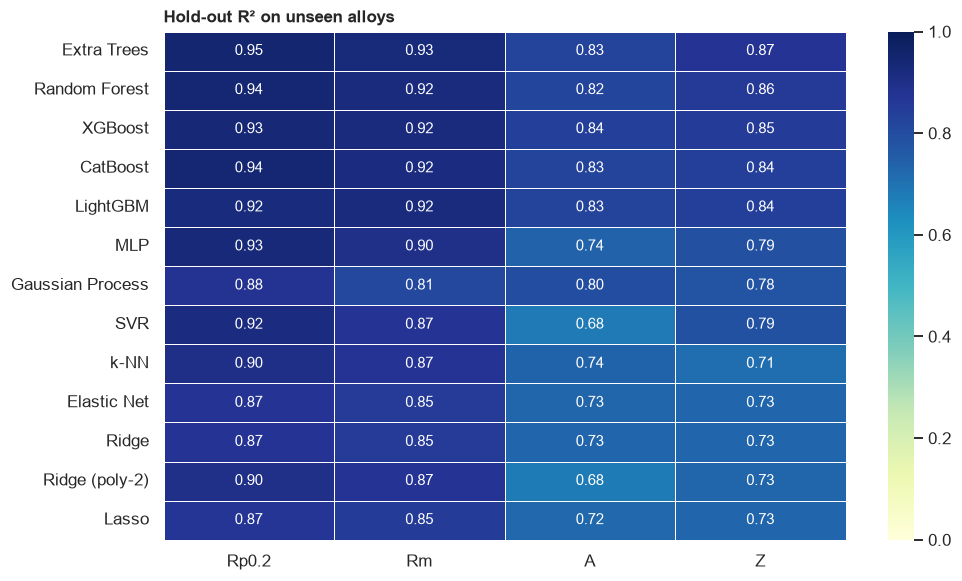

In [20]:
def cluster_bootstrap(y, p, groups, n=1000):
    r = np.random.default_rng(SEED)
    frame = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p), "g": np.asarray(groups)})
    ids = frame["g"].unique()
    parts = {k: v for k, v in frame.groupby("g")}
    out = []
    for _ in range(n):
        s = pd.concat([parts[i] for i in r.choice(ids, len(ids))])
        out.append((r2_score(s["y"], s["p"]), rmse(s["y"], s["p"])))
    return np.percentile(out, [2.5, 97.5], axis=0)


test_pred, rows = {}, []
for prop in PROPS:
    X, y, g = target_data(test, prop)
    for key in MODELS:
        p = tuned[(prop, key)].predict(X)
        test_pred[(prop, key)] = p
        rows.append({"property": PROP_SHORT[prop], "model": MODELS[key], "family": FAMILY[key], "R²": r2_score(y, p),
                     "RMSE": rmse(y, p), "MAE": mean_absolute_error(y, p),
                     "MAPE %": 100 * np.mean(np.abs((y - p) / y)), "champion": key == CHAMPIONS[prop]})
holdout = pd.DataFrame(rows)
keep_table(holdout, "9_holdout")

champ_rows = []
for prop, key in CHAMPIONS.items():
    X, y, g = target_data(test, prop)
    ci = cluster_bootstrap(y, test_pred[(prop, key)], g)
    h = holdout[(holdout["property"] == PROP_SHORT[prop]) & (holdout["model"] == MODELS[key])].iloc[0]
    champ_rows.append({"property": PROP_LABELS[prop], "champion": MODELS[key], "R²": h["R²"],
                       "R² 95% CI": f"{ci[0, 0]:.3f} – {ci[1, 0]:.3f}", "RMSE": h["RMSE"],
                       "RMSE 95% CI": f"{ci[0, 1]:.1f} – {ci[1, 1]:.1f}", "MAE": h["MAE"], "MAPE %": h["MAPE %"]})
champion_summary = pd.DataFrame(champ_rows).set_index("property")
display(champion_summary.style.format(precision=3))

fig, ax = plt.subplots(figsize=(10, 6))
piv = holdout.pivot(index="model", columns="property", values="R²")[[PROP_SHORT[p] for p in PROPS]]
piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]
sns.heatmap(piv, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.6, ax=ax)
ax.set(title="Hold-out R² on unseen alloys", xlabel="", ylabel="")
keep(fig, "9_1_holdout_heatmap")
plt.show()

### 9.2 Parity and residual structure
Parity plots for each champion, with points coloured by test temperature, and residuals plotted against temperature. Residuals that change systematically with temperature would mean part of the temperature dependence has not been captured.

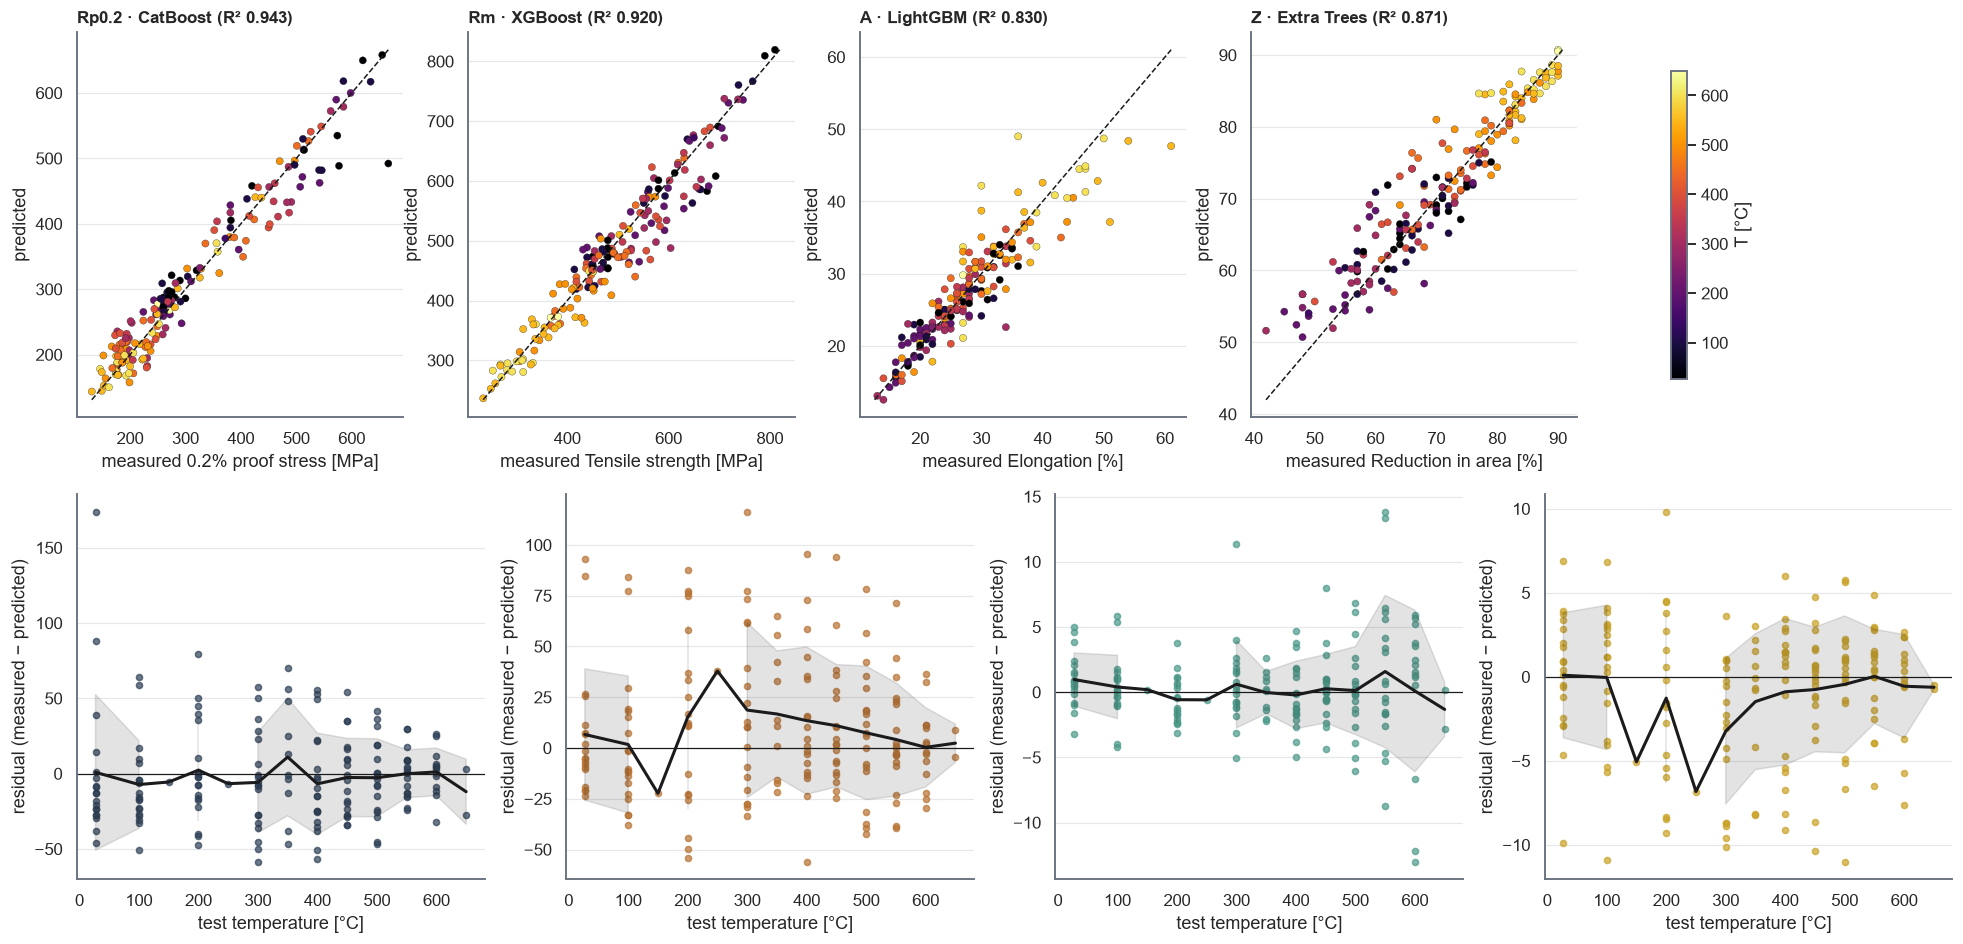

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for j, prop in enumerate(PROPS):
    X, y, g = target_data(test, prop)
    p = test_pred[(prop, CHAMPIONS[prop])]
    ax = axes[0, j]
    sc = ax.scatter(y, p, c=X["temperature_C"], cmap="inferno", s=22, edgecolor="k", lw=0.2)
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(title=f"{PROP_SHORT[prop]} · {MODELS[CHAMPIONS[prop]]} (R² {r2_score(y, p):.3f})",
           xlabel=f"measured {PROP_LABELS[prop]}", ylabel="predicted")
    ax = axes[1, j]
    resid = y - p
    ax.scatter(X["temperature_C"], resid, s=16, color=PROP_COLORS[prop], alpha=0.7)
    band = pd.DataFrame({"T": X["temperature_C"], "r": resid}).groupby("T")["r"].agg(["mean", "std"])
    ax.plot(band.index, band["mean"], color=GRAPHITE, lw=2)
    ax.fill_between(band.index, band["mean"] - band["std"], band["mean"] + band["std"], color=GRAPHITE, alpha=0.12)
    ax.axhline(0, c="k", lw=0.8)
    ax.set(xlabel="test temperature [°C]", ylabel="residual (measured − predicted)")
fig.colorbar(sc, ax=axes[0, :], shrink=0.8, label="T [°C]")
keep(fig, "9_2_parity_residuals")
plt.show()

### 9.3 Temperature curves of unseen alloys
Measured and predicted strength and ductility curves for six test alloys. Each prediction is a continuous curve computed on a dense temperature grid. This checks whether the models reproduce the *shape* of the temperature response, including non-monotonic behaviour such as strength recovering in an intermediate temperature range, and not only the individual points.

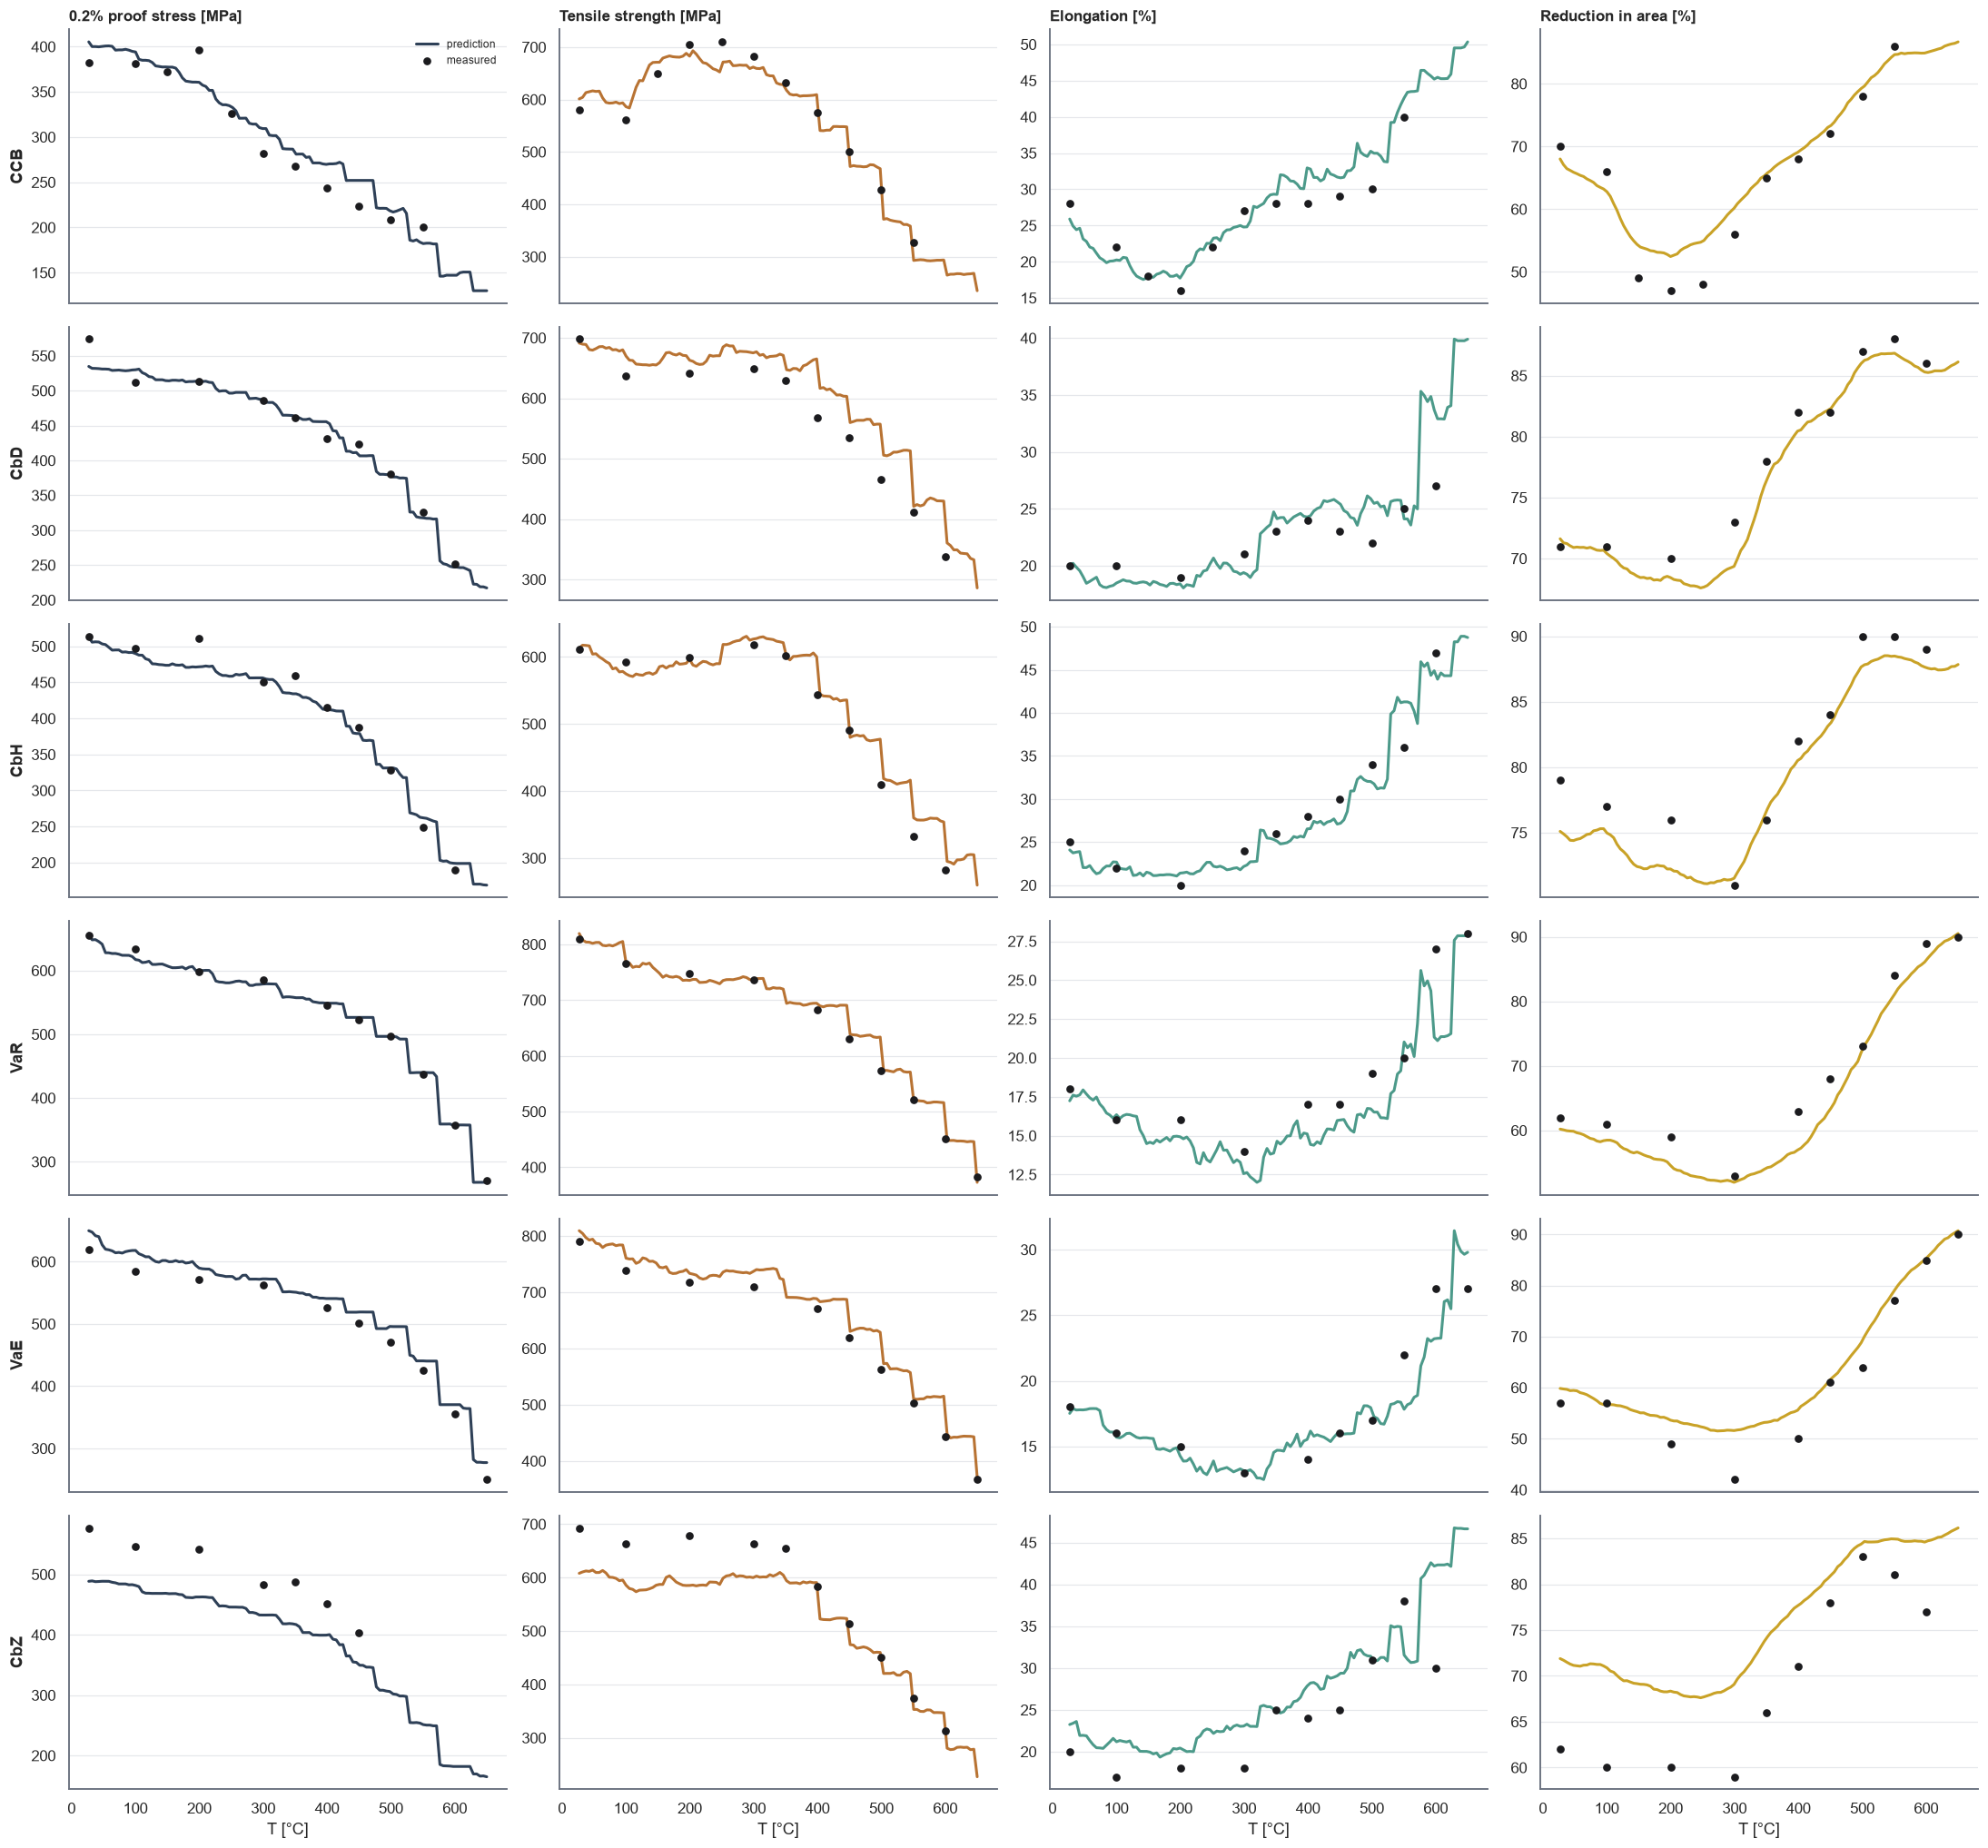

In [22]:
T_GRID = np.linspace(clean["temperature_C"].min(), clean["temperature_C"].max(), 120)


def curve(model, composition):
    frame = pd.DataFrame({**{e: np.full(len(T_GRID), composition[e]) for e in ELEMENTS}, "temperature_C": T_GRID})
    return model.predict(frame[RAW_INPUTS])


show_alloys = test.groupby("alloy_id").size().sort_values(ascending=False).index[:6]
fig, axes = plt.subplots(len(show_alloys), 4, figsize=(20, 3.1 * len(show_alloys)), sharex=True)
for i, alloy in enumerate(show_alloys):
    g = test[test["alloy_id"] == alloy].sort_values("temperature_C")
    comp = g[ELEMENTS].iloc[0]
    for j, prop in enumerate(PROPS):
        ax = axes[i, j]
        ax.plot(T_GRID, curve(tuned[(prop, CHAMPIONS[prop])], comp), color=PROP_COLORS[prop], lw=2, label="prediction")
        ax.scatter(g["temperature_C"], g[prop], color=GRAPHITE, s=22, zorder=5, label="measured")
        if i == 0:
            ax.set_title(PROP_LABELS[prop])
        if j == 0:
            ax.set_ylabel(alloy, fontweight="bold")
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("T [°C]")
fig.tight_layout()
keep(fig, "9_3_test_curves")
plt.show()

### 9.4 Physical consistency of joint predictions
Each property is predicted by a separate model, so nothing forces $\hat R_{p0.2} \le \hat R_m$. The share of test points where this constraint is violated is a direct check of physical plausibility.

In [23]:
both = test.dropna(subset=["proof_stress_MPa", "tensile_strength_MPa"])
pp = tuned[("proof_stress_MPa", CHAMPIONS["proof_stress_MPa"])].predict(both[RAW_INPUTS])
pt = tuned[("tensile_strength_MPa", CHAMPIONS["tensile_strength_MPa"])].predict(both[RAW_INPUTS])
viol = pp > pt
say(f"Predicted Rp0.2 > Rm in **{viol.mean():.1%}** of test points ({viol.sum()} of {len(viol)}). "
    f"Predicted yield ratio: median {np.median(pp / pt):.3f} vs measured {np.median(both['yield_ratio']):.3f}.")

Predicted Rp0.2 > Rm in **0.0%** of test points (0 of 177). Predicted yield ratio: median 0.609 vs measured 0.583.

## 10 · Prediction Uncertainty

### 10.1 Split-conformal intervals
For each champion, the absolute residuals of out-of-fold (grouped-CV) predictions on the training alloys set the half-width $q$ of a distribution-free prediction interval $\hat y \pm q$ at the $1-\alpha$ level. Coverage and interval width are then checked on the unseen test alloys.

### 10.2 Gaussian-process predictive intervals
The tuned Gaussian process provides a predictive standard deviation for every point, so the width of its interval adapts to how far the input lies from the training data. Its empirical coverage is compared with the nominal level.

**Nominal coverage: 90%**

,champion,conformal half-width,conformal coverage,GP mean half-width,GP coverage
property,,,,,
Rp0.2,CatBoost,54.070,93.2%,37.825,71.2%
Rm,XGBoost,47.679,85.0%,29.465,62.8%
A,LightGBM,5.374,90.0%,4.260,80.6%
Z,Extra Trees,7.719,89.9%,6.151,82.1%


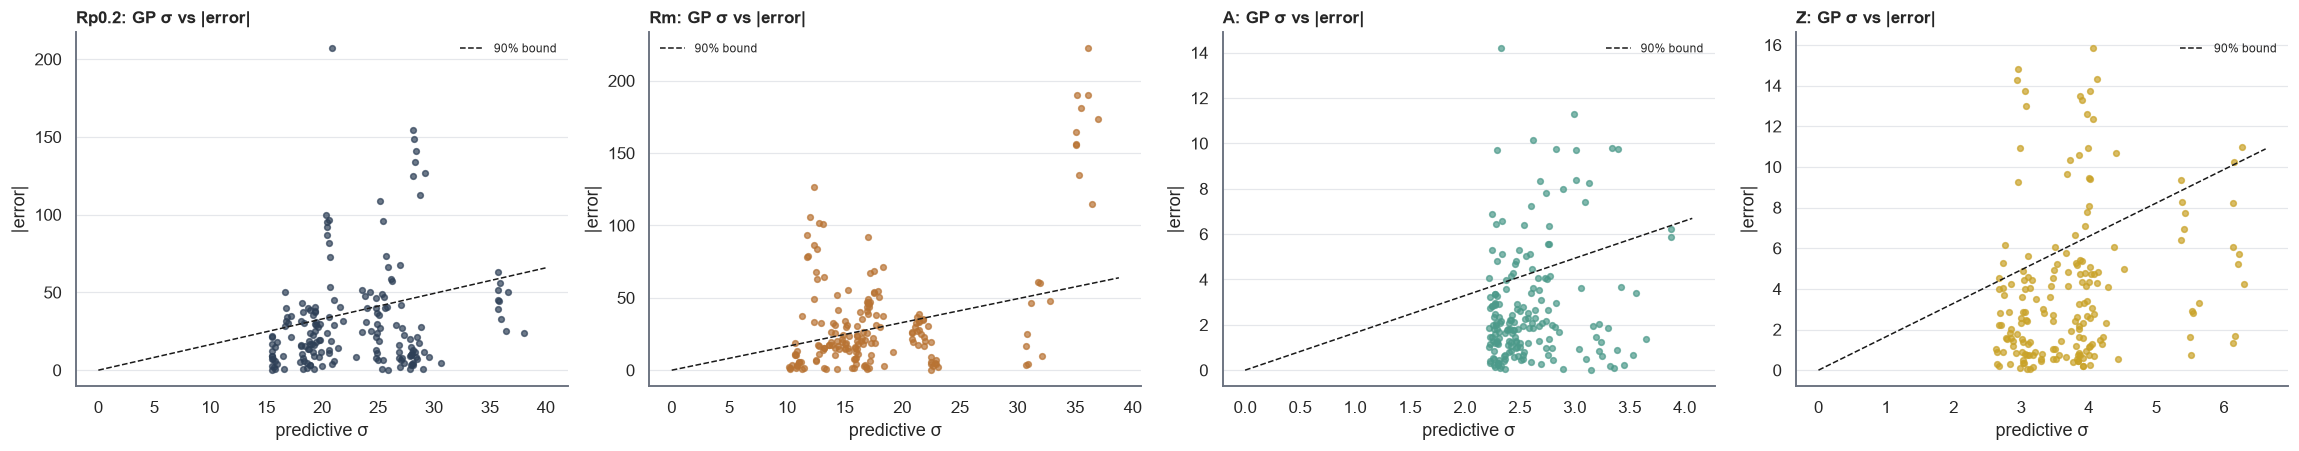

In [24]:
alpha = CFG["conformal_alpha"]
z = stats.norm.ppf(1 - alpha / 2)
unc_rows, conformal_q = [], {}
for prop in PROPS:
    Xtr, ytr, gtr = target_data(train, prop)
    Xte, yte, _ = target_data(test, prop)
    key = CHAMPIONS[prop]
    oof = cross_val_predict(clone(tuned[(prop, key)]), Xtr, ytr, cv=GCV, groups=gtr, n_jobs=-1)
    scores_ = np.abs(ytr - oof)
    n = len(scores_)
    q = np.quantile(scores_, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n))
    conformal_q[prop] = float(q)
    p = test_pred[(prop, key)]
    gp_mean, gp_sd = tuned[(prop, "GP")].predict(Xte, return_std=True)
    unc_rows.append({"property": PROP_SHORT[prop], "champion": MODELS[key],
                     "conformal half-width": q, "conformal coverage": np.mean(np.abs(yte - p) <= q),
                     "GP mean half-width": np.mean(z * gp_sd), "GP coverage": np.mean(np.abs(yte - gp_mean) <= z * gp_sd)})
uncertainty = pd.DataFrame(unc_rows).set_index("property")
say(f"**Nominal coverage: {1 - alpha:.0%}**")
display(uncertainty.style.format(precision=3).format("{:.1%}", subset=["conformal coverage", "GP coverage"]))

fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
for ax, prop in zip(axes, PROPS):
    Xte, yte, _ = target_data(test, prop)
    gp_mean, gp_sd = tuned[(prop, "GP")].predict(Xte, return_std=True)
    err = np.abs(yte - gp_mean)
    ax.scatter(gp_sd, err, s=14, color=PROP_COLORS[prop], alpha=0.7)
    xs = np.linspace(0, gp_sd.max() * 1.05, 50)
    ax.plot(xs, z * xs, "k--", lw=1, label=f"{1 - alpha:.0%} bound")
    ax.set(title=f"{PROP_SHORT[prop]}: GP σ vs |error|", xlabel="predictive σ", ylabel="|error|")
    ax.legend(fontsize=8)
fig.tight_layout()
keep(fig, "10_gp_uncertainty")
plt.show()

## 11 · Interpretation

### 11.1 Composition-aware permutation importance
Each **raw input** (an element or the temperature) is shuffled in turn across the test set, and all derived features (CE and the temperature interactions) are recomputed from the shuffled input. The increase in RMSE measures the total influence of that input, including its effect through every feature derived from it. This avoids the misleading split of importance between a variable and its engineered interactions.

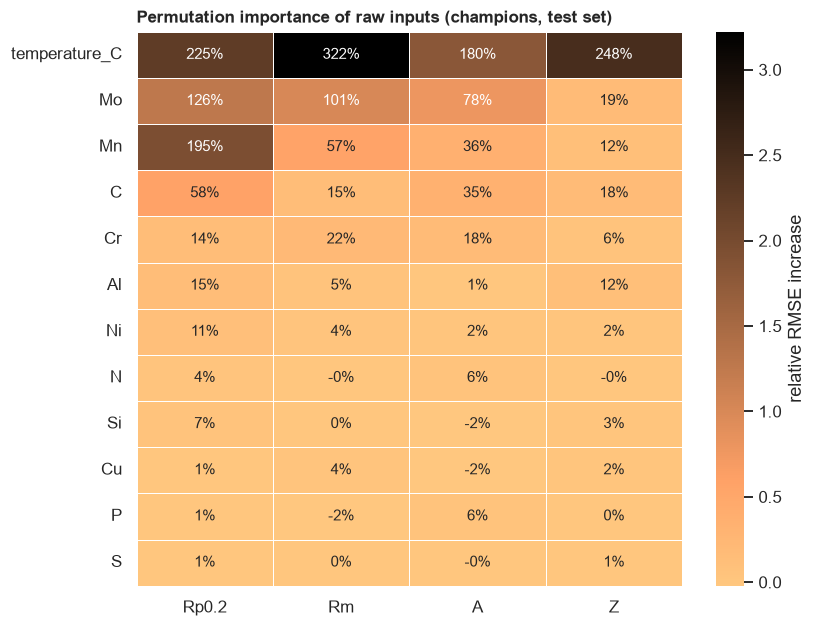

In [25]:
def raw_permutation_importance(model, X, y, repeats=15):
    r = np.random.default_rng(SEED)
    base = rmse(y, model.predict(X))
    out = {}
    for col in RAW_INPUTS:
        vals = []
        for _ in range(repeats):
            Xp = X.copy()
            Xp[col] = r.permutation(Xp[col].to_numpy())
            vals.append(rmse(y, model.predict(Xp)) - base)
        out[col] = np.mean(vals) / base
    return pd.Series(out)


imp = {}
for prop in PROPS:
    Xte, yte, _ = target_data(test, prop)
    imp[PROP_SHORT[prop]] = raw_permutation_importance(tuned[(prop, CHAMPIONS[prop])], Xte, yte)
imp = pd.DataFrame(imp)
imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 0.42 * len(imp) + 1.5))
sns.heatmap(imp, annot=True, fmt=".0%", cmap="copper_r", ax=ax, linewidths=0.5, cbar_kws={"label": "relative RMSE increase"})
ax.set(title="Permutation importance of raw inputs (champions, test set)", xlabel="", ylabel="")
keep(fig, "11_1_importance")
plt.show()
keep_table(imp, "11_1_importance")

### 11.2 Individual conditional expectation (ICE)
For the four most influential inputs overall, each test composition is varied along that input while its other inputs are held fixed. Thin lines show individual alloys and the thick line shows the average response. The profiles show the direction and shape of each input's effect as the models have learned it, and can be checked against known metallurgy, such as carbon strengthening the steel at the expense of ductility.

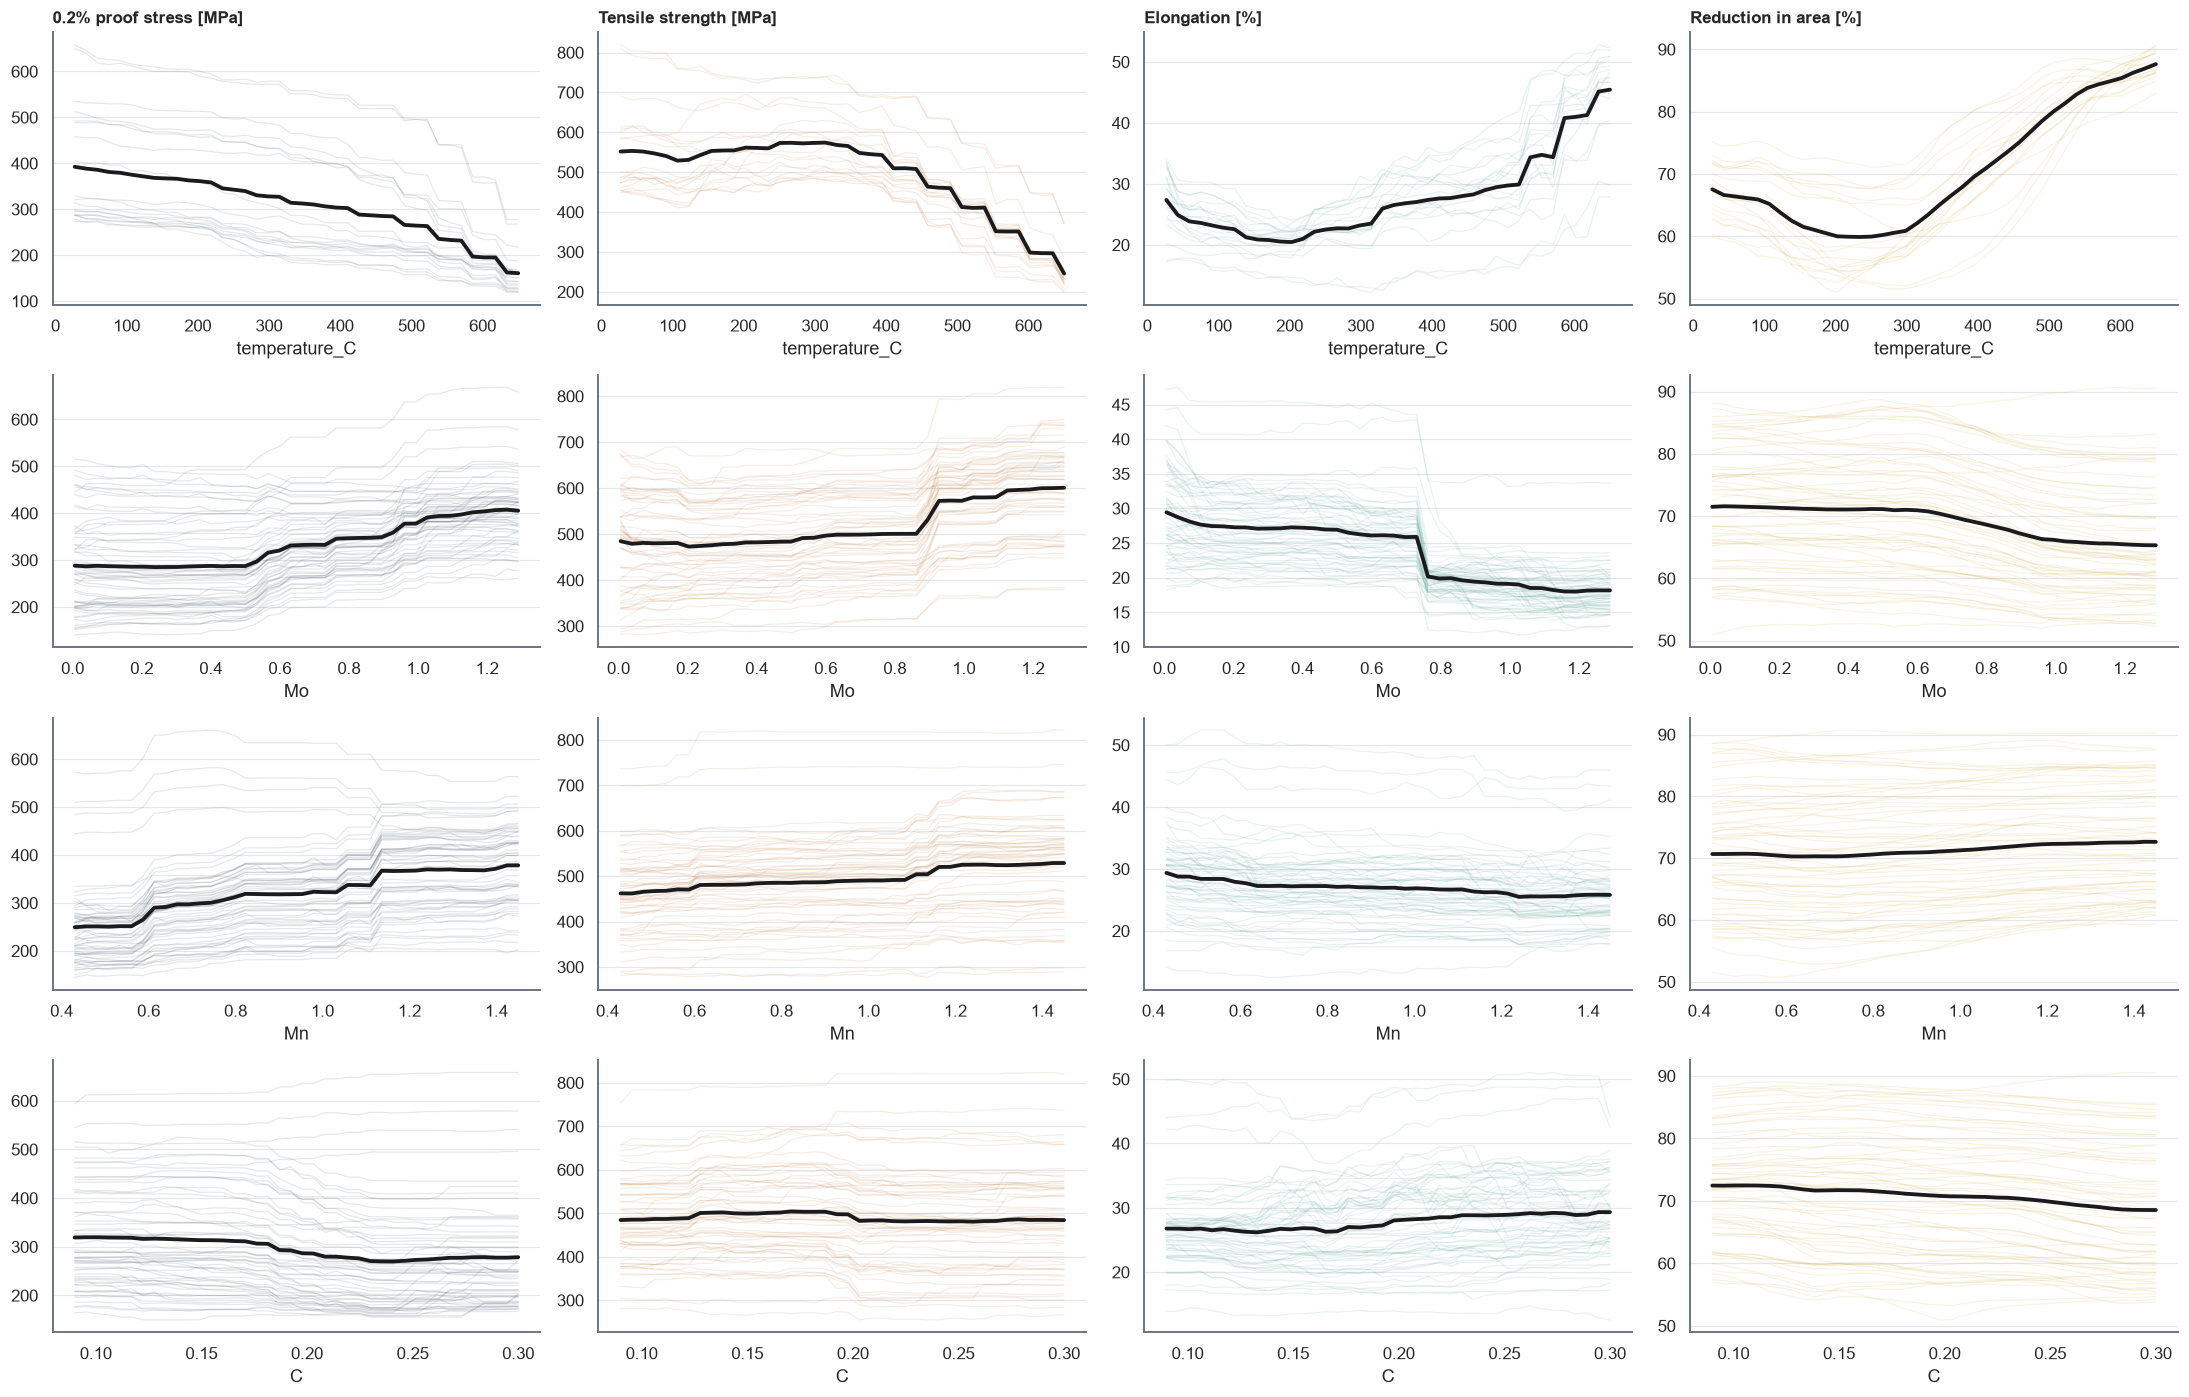

In [26]:
top_inputs = imp.mean(axis=1).index[:4].tolist()
fig, axes = plt.subplots(len(top_inputs), 4, figsize=(20, 3.2 * len(top_inputs)))
for i, col in enumerate(top_inputs):
    grid_vals = np.linspace(*clean[col].quantile([0.02, 0.98]), 40)
    for j, prop in enumerate(PROPS):
        Xte, _, _ = target_data(test, prop)
        base = Xte.drop_duplicates(subset=ELEMENTS) if col == "temperature_C" else Xte
        base = base.sample(min(60, len(base)), random_state=SEED)
        model = tuned[(prop, CHAMPIONS[prop])]
        curves = np.column_stack([model.predict(base.assign(**{col: v})) for v in grid_vals])
        ax = axes[i, j]
        ax.plot(grid_vals, curves.T, color=PROP_COLORS[prop], alpha=0.12, lw=0.8)
        ax.plot(grid_vals, curves.mean(axis=0), color=GRAPHITE, lw=2.5)
        if i == 0:
            ax.set_title(PROP_LABELS[prop])
        ax.set_xlabel(col)
fig.tight_layout()
keep(fig, "11_2_ice")
plt.show()

## 12 · Extrapolation Diagnostics and Data Requirements

### 12.1 Error versus compositional novelty
For each test alloy, novelty is measured as the Euclidean distance, in standardised composition space, to the nearest training alloy. If the error grows with novelty, the models are interpolating between known steels and are not capturing general composition–property laws, and their predictions should only be trusted within the region covered by the training data.

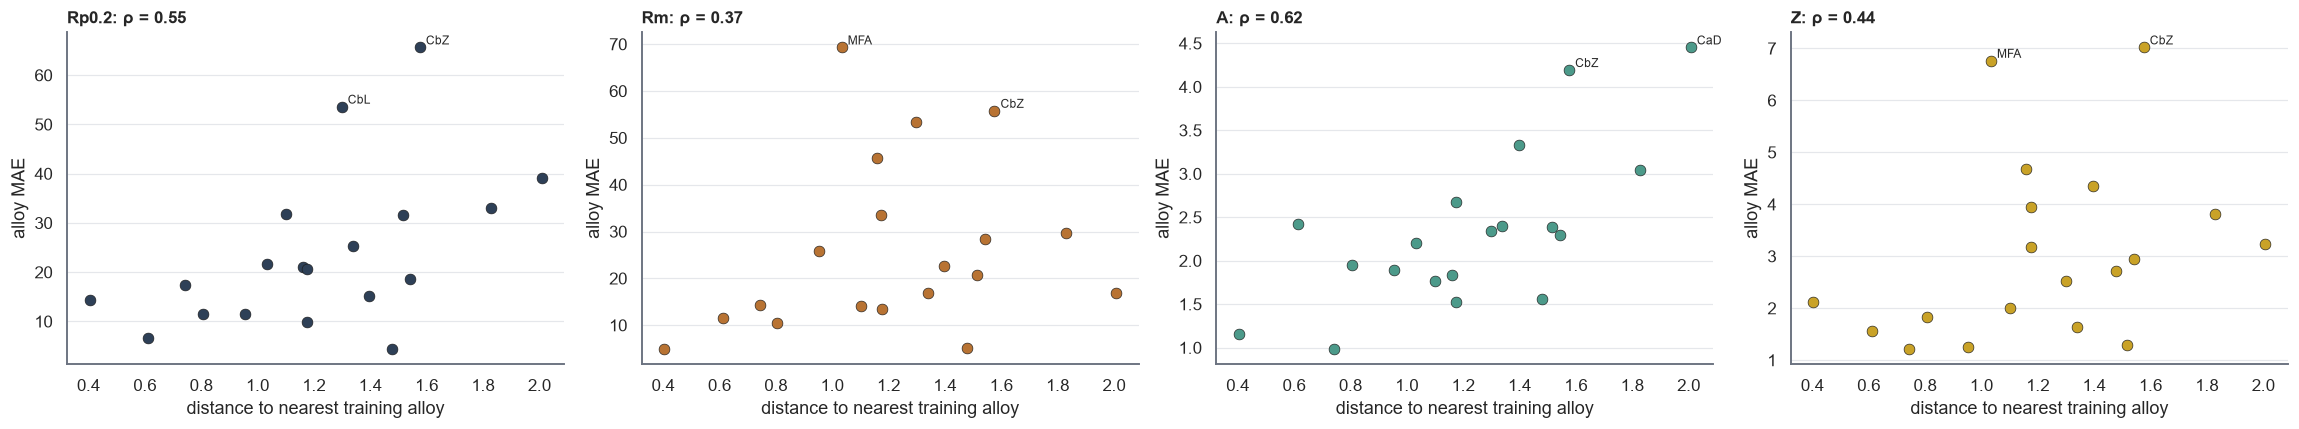

,"Spearman ρ (novelty, MAE)",p
property,,
Rp0.2,0.549,0.015
Rm,0.372,0.117
A,0.616,0.005
Z,0.440,0.059


In [27]:
comp_scaler = StandardScaler().fit(alloy_comp.loc[train["alloy_id"].unique(), ELEMENTS])
nn = NearestNeighbors(n_neighbors=1).fit(comp_scaler.transform(alloy_comp.loc[train["alloy_id"].unique(), ELEMENTS]))
test_alloys = test["alloy_id"].unique()
novelty = pd.Series(nn.kneighbors(comp_scaler.transform(alloy_comp.loc[test_alloys, ELEMENTS]))[0][:, 0], index=test_alloys)

fig, axes = plt.subplots(1, 4, figsize=(21, 4))
nov_rows = []
for ax, prop in zip(axes, PROPS):
    Xte, yte, gte = target_data(test, prop)
    err = pd.Series(np.abs(yte.to_numpy() - test_pred[(prop, CHAMPIONS[prop])]), index=gte.to_numpy()).groupby(level=0).mean()
    d = novelty.loc[err.index]
    rho_n, p_n = stats.spearmanr(d, err)
    nov_rows.append({"property": PROP_SHORT[prop], "Spearman ρ (novelty, MAE)": rho_n, "p": p_n})
    ax.scatter(d, err, s=50, color=PROP_COLORS[prop], edgecolor="k", lw=0.4)
    for a in err.nlargest(2).index:
        ax.annotate(a, (d[a], err[a]), fontsize=8, xytext=(4, 2), textcoords="offset points")
    ax.set(title=f"{PROP_SHORT[prop]}: ρ = {rho_n:.2f}", xlabel="distance to nearest training alloy", ylabel="alloy MAE")
fig.tight_layout()
keep(fig, "12_1_novelty")
plt.show()
display(pd.DataFrame(nov_rows).set_index("property").style.format(precision=3))

### 12.2 How many alloys are needed?
Each champion is retrained on random subsets of the training alloys, from 30 % to 100 % of them, three repetitions per size, and evaluated on the fixed test alloys. The shape of this learning curve shows whether collecting data for more steel grades would still improve accuracy.

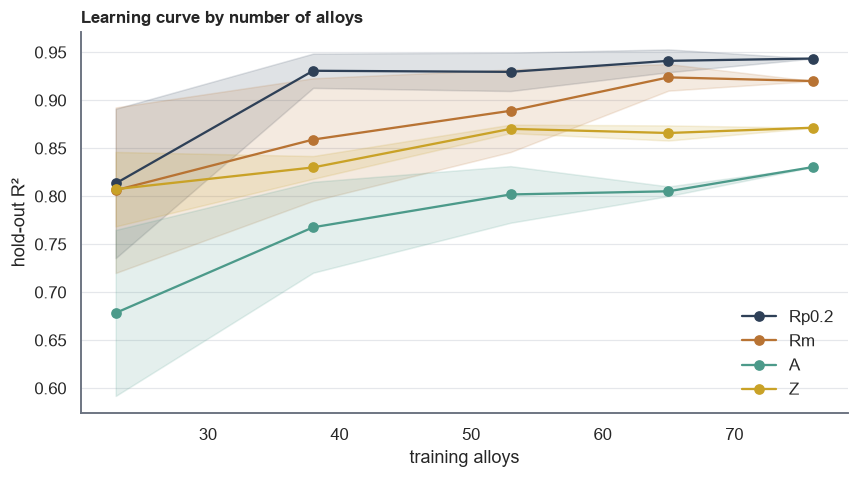

In [28]:
fractions = [0.3, 0.5, 0.7, 0.85, 1.0]
train_alloys = train["alloy_id"].unique()
r = np.random.default_rng(SEED)
lc_rows = []
for prop in PROPS:
    Xte, yte, _ = target_data(test, prop)
    for f in fractions:
        for rep in range(1 if f == 1.0 else 3):
            chosen = r.choice(train_alloys, max(5, int(round(f * len(train_alloys)))), replace=False)
            Xs, ys, _ = target_data(train[train["alloy_id"].isin(chosen)], prop)
            m = clone(tuned[(prop, CHAMPIONS[prop])]).fit(Xs, ys)
            lc_rows.append({"property": prop, "alloys": len(chosen), "R2": r2_score(yte, m.predict(Xte))})
lc = pd.DataFrame(lc_rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
for prop in PROPS:
    s = lc[lc["property"] == prop].groupby("alloys")["R2"].agg(["mean", "std"]).fillna(0)
    ax.plot(s.index, s["mean"], "o-", color=PROP_COLORS[prop], label=PROP_SHORT[prop])
    ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=PROP_COLORS[prop], alpha=0.15)
ax.set(xlabel="training alloys", ylabel="hold-out R²", title="Learning curve by number of alloys")
ax.legend()
keep(fig, "12_2_learning_curve")
plt.show()

## 13 · Alloy Design Tool and Export

### 13.1 Property curves for a candidate composition
`predict_properties()` returns predicted curves of all four properties against temperature for any composition, with conformal prediction bands, and flags compositions that lie outside the range covered by the training data. It is demonstrated on the median training composition and on a higher-carbon variant of it.

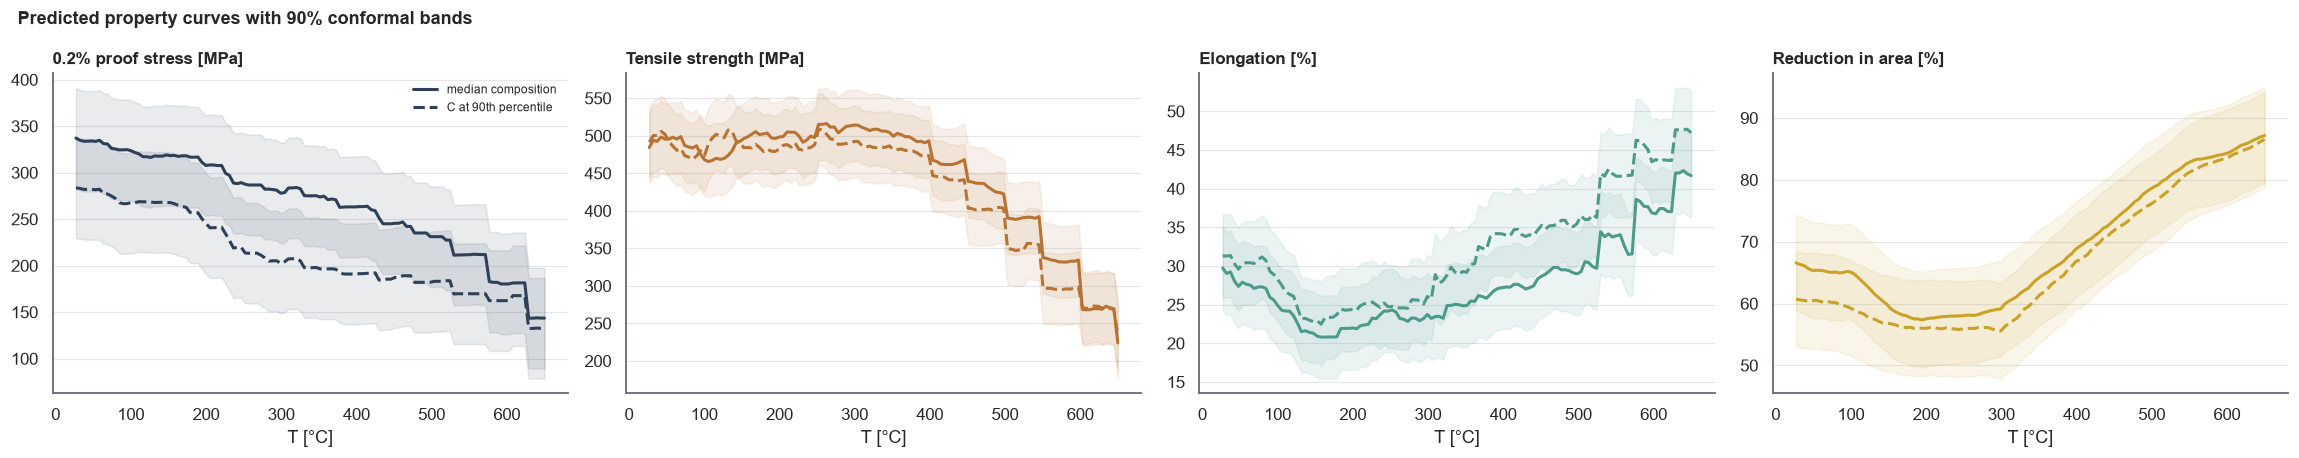

Elements outside training range (high-C variant): none


In [29]:
TRAIN_RANGE = alloy_comp.loc[train_alloys, ELEMENTS].agg(["min", "max"])


def predict_properties(composition, temperatures=T_GRID):
    comp = {e: float(composition.get(e, 0.0)) for e in ELEMENTS}
    frame = pd.DataFrame({**{e: np.full(len(temperatures), v) for e, v in comp.items()}, "temperature_C": temperatures})
    out = pd.DataFrame({"temperature_C": temperatures})
    for prop in PROPS:
        pred = tuned[(prop, CHAMPIONS[prop])].predict(frame[RAW_INPUTS])
        out[prop], out[f"{prop}_lo"], out[f"{prop}_hi"] = pred, pred - conformal_q[prop], pred + conformal_q[prop]
    outside = [e for e, v in comp.items() if not TRAIN_RANGE.loc["min", e] <= v <= TRAIN_RANGE.loc["max", e]]
    out.attrs["outside_training_range"] = outside
    return out


median_comp = alloy_comp.loc[train_alloys, ELEMENTS].median().to_dict()
high_c = {**median_comp, "C": alloy_comp.loc[train_alloys, "C"].quantile(0.9)}
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
for comp, label, ls in [(median_comp, "median composition", "-"), (high_c, "C at 90th percentile", "--")]:
    res = predict_properties(comp)
    for ax, prop in zip(axes, PROPS):
        ax.plot(res["temperature_C"], res[prop], ls=ls, color=PROP_COLORS[prop], lw=2, label=label)
        ax.fill_between(res["temperature_C"], res[f"{prop}_lo"], res[f"{prop}_hi"], color=PROP_COLORS[prop], alpha=0.1)
        ax.set(title=PROP_LABELS[prop], xlabel="T [°C]")
axes[0].legend(fontsize=8)
fig.suptitle(f"Predicted property curves with {1 - alpha:.0%} conformal bands", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
keep(fig, "13_1_design_tool")
plt.show()
print("Elements outside training range (high-C variant):", predict_properties(high_c).attrs["outside_training_range"] or "none")

### 13.2 Export
Saves the four champion pipelines, the conformal half-widths, the training composition ranges and the list of inputs to a single bundle. The test-set predictions are also saved as a CSV (the output of the original analysis), and all figures and tables are packaged into an archive. The feature-engineering function `engineer` must be defined in the session before the bundle is loaded.

In [30]:
bundle = {"models": {p: tuned[(p, CHAMPIONS[p])] for p in PROPS}, "champions": {p: MODELS[k] for p, k in CHAMPIONS.items()},
          "feature_sets": FEATURE_CHOICE, "conformal_halfwidth": conformal_q, "alpha": alpha,
          "elements": ELEMENTS, "raw_inputs": RAW_INPUTS, "training_range": TRAIN_RANGE.to_dict()}
joblib.dump(bundle, PATHS["models"] / "steel_property_models.joblib")

card = {"created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "validation": "alloy-grouped (GroupKFold) with unseen-alloy hold-out",
        "champions": bundle["champions"], "feature_sets": FEATURE_CHOICE,
        "holdout": champion_summary.reset_index().to_dict("records"),
        "conformal_halfwidth": conformal_q, "excluded_inputs": EXCLUDED, "versions": VERSIONS}
(PATHS["models"] / "model_card.json").write_text(json.dumps(card, indent=2, default=str))

pred_df = test[["alloy_id"] + RAW_INPUTS + PROPS].copy()
for prop in PROPS:
    pred_df[f"pred_{prop}"] = tuned[(prop, CHAMPIONS[prop])].predict(pred_df[RAW_INPUTS])
pred_df.to_csv(PATHS["tables"] / "test_predictions.csv", index=False)

archive = shutil.make_archive(str(BASE), "zip", BASE)
print(f"Archive: {archive} ({Path(archive).stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Archive: C:\Users\Ekta Jain\Downloads\nb_run\repos\low-alloy-steel-properties\notebooks\steel_property_study.zip (21.1 MB)


## Summary
Generated from this run.

In [31]:
best_family = holdout[holdout["champion"]]["family"].value_counts()
lin_best = holdout[holdout["family"] == "linear"].groupby("property")["R²"].max()
tree_best = holdout[holdout["family"].str.contains("trees")].groupby("property")["R²"].max()
fs_note = ", ".join(f"{PROP_SHORT[p]}: {fs}" for p, fs in FEATURE_CHOICE.items())
say(f"""
1. **Data integrity.** There are {len(steel)} tests on {steel['alloy_id'].nunique()} alloys. {len(flag_table)} tests contain at least one statistically flagged value (robust |z| > {CFG['outlier_z']}), and {int(violations.any(axis=1).sum())} tests violate a physical constraint. Composition variables excluded for sparsity: {', '.join(EXCLUDED) or 'none'}.
2. **Validation protocol.** Row-wise CV overstates R² by between {leak['optimism (ΔR²)'].min():.2f} and {leak['optimism (ΔR²)'].max():.2f} compared with alloy-grouped CV. Row-wise scores therefore do not show how well the models predict new steels.
3. **Feature sets.** The best feature set for each property is {fs_note}.
4. **Champions on unseen alloys.** """ + "; ".join(
    f"{PROP_SHORT[p]} – {MODELS[k]} (R² {champion_summary.loc[PROP_LABELS[p], 'R²']:.3f}, RMSE {champion_summary.loc[PROP_LABELS[p], 'RMSE']:.1f})"
    for p, k in CHAMPIONS.items()) + f""".
5. **Model families.** The best tree ensemble outperforms the best linear model by a mean of {(tree_best - lin_best).mean():+.3f} in hold-out R² across the four properties.
6. **Uncertainty.** The conformal intervals reach {uncertainty['conformal coverage'].mean():.0%} average coverage against a nominal {1 - alpha:.0%}. The Gaussian-process intervals reach {uncertainty['GP coverage'].mean():.0%}.
7. **Physics.** The separately trained champions predict Rp0.2 > Rm for {viol.mean():.1%} of test points. The most influential inputs overall are {', '.join(imp.mean(axis=1).index[:3])}.
""")


1. **Data integrity.** There are 915 tests on 95 alloys. 38 tests contain at least one statistically flagged value (robust |z| > 4.0), and 1 tests violate a physical constraint. Composition variables excluded for sparsity: V, Ceq, Nb_Ta.
2. **Validation protocol.** Row-wise CV overstates R² by between 0.01 and 0.09 compared with alloy-grouped CV. Row-wise scores therefore do not show how well the models predict new steels.
3. **Feature sets.** The best feature set for each property is A: full, Rp0.2: full, Z: full, Rm: full.
4. **Champions on unseen alloys.** A – LightGBM (R² 0.830, RMSE 3.4); Rp0.2 – CatBoost (R² 0.943, RMSE 31.4); Z – Extra Trees (R² 0.871, RMSE 4.1); Rm – XGBoost (R² 0.920, RMSE 35.0).
5. **Model families.** The best tree ensemble outperforms the best linear model by a mean of +0.088 in hold-out R² across the four properties.
6. **Uncertainty.** The conformal intervals reach 90% average coverage against a nominal 90%. The Gaussian-process intervals reach 74%.
7. **Physics.** The separately trained champions predict Rp0.2 > Rm for 0.0% of test points. The most influential inputs overall are temperature_C, Mo, Mn.


---
**References.** NIMS MatNavi materials database · Nadeau & Bengio (2003), *Inference for the generalization error* · Vovk, Gammerman & Shafer (2005), *Algorithmic Learning in a Random World* (conformal prediction) · Rasmussen & Williams (2006), *Gaussian Processes for Machine Learning* · IIW carbon equivalent (Dearden & O'Neill, 1940).